# H11 — Fixed-grid tile-size and adaptive ROI study · all six models (LEVIR-CD)

**Question:** How do 32, 64, 128 and 256-pixel grids change ROI suitability for *every* existing WHERE model, and can adjacent-tile merging reduce crop count without wasting context?

**Comparisons and controls**

- All six original models: `light_full`, `medium_full`, `heavy_full`, `light_resized`, `medium_resized`, `heavy_resized`.
- Matched validation thresholds **0.35 and 0.70**, matching H10. Grid tile sizes **32/64/128/256**, with context margins **0/8/16/32 px** (added around each selected tile).
- Adaptive merging on **32/64/128-pixel grids**: join adjacent positive tiles only if the merged bounding box is not too large or too empty. This experimental algorithm uses **predictions only**, never ground truth.
- The project's original `satchange.semantic.roi.extract_rois` at `min_crop_size=128` is retained as a baseline.
- Report **union coverage and single-crop coverage separately**: a GT object may be captured by the *union* of 32-pixel crops yet not appear almost completely in *any single crop*.
- Crop count, summed processed area (overlaps count repeatedly), unique forwarded area, false-crop fraction, fragmentation, and two **hypothetical** WHAT cost proxies are recorded. No real WHAT-model inference is measured.
- Choose optional model-specific policies on a fixed half of validation (**development**); evaluate these on the other half (**internal audit**). Neither half is an independent test set.

**Run All is enabled by default.** No training, downloads, inference from checkpoints, test-set access, or changes to `src/satchange/`.

**Important:** `32 × 32` refers to the **original 1024-pixel image coordinates**, *including for Resized models*. The Resized score maps are interpolated to the original GT shape by the unchanged H1–H5 project adapter. A WHAT model with fixed input resolution may *not* be 16× cheaper for a crop with 16× fewer source pixels.

## 0 — Configuration: all six models and all tile sizes run by default

In [1]:
from pathlib import Path
PROJECT_ROOT = Path('../..')
V1_RUN = 'H1_H5_v1'
OUT_NAME = 'H11_grid_tile_size_all_models'

MODELS = ('light_full', 'medium_full', 'heavy_full', 'light_resized', 'medium_resized', 'heavy_resized')
THRESHOLDS = (0.35, 0.70)
GRID_SIZES = (32, 64, 128, 256)
CONTEXT_MARGINS = (0, 8, 16, 32)
ADAPTIVE_SIZES = (32, 64, 128)
RUN_ADAPTIVE = True
RUN_PROJECT_BASELINE = True
RUN_CASE_VISUALS = True
CASE_INDICES = (5, 32)

# Adaptive groups only when the merged rectangle is compact and not too large.
ADAPTIVE_MAX_BBOX_AREA_FRACTION = 0.06
ADAPTIVE_MIN_FILL_RATIO = 0.55

# Evaluation uses cached validation scores; optional development/audit split remains fixed.
INTERNAL_AUDIT_SEED = 1029  # Keep the same split as H10.
BOOTSTRAP_REPS = 2000
BOOTSTRAP_SEED = 20301030
TARGET_COVERAGE_95 = {'full': 0.975, 'resized': 0.935}

# Computational scenarios, NOT measured runtime or semantic-model accuracy.
WHAT_FIXED_INPUT_SIDE = 256  # Each crop resized to 256×256 for hypothetical fixed-input WHAT model.
WHAT_PER_CROP_MS_SCENARIO = (0.5, 2.0, 10.0)

# Resume after interruption: completed (model, threshold) shards are reused only if config is identical.
RESUME = True

print('Models:', MODELS)
print('Grid sizes:', GRID_SIZES, '| margins:', CONTEXT_MARGINS)
print('Adaptive:', RUN_ADAPTIVE, '| project baseline:', RUN_PROJECT_BASELINE)

Models: ('light_full', 'medium_full', 'heavy_full', 'light_resized', 'medium_resized', 'heavy_resized')
Grid sizes: (32, 64, 128, 256) | margins: (0, 8, 16, 32)
Adaptive: True | project baseline: True


## 1 — Reuse the original experiment adapter, unchanged

This is **the same embedded H1–H5 core from notebook 06** that was used in H09/H10. Its SHA-256 is checked against the original manifest before any scores are read. This reuses existing checkpoint definitions, GT component protocol and probability caches; it does **not** implement a new inference stack.

In [2]:
CORE_SOURCE = r'''"""Read-only LEVIR-CD inference and exploratory H1--H5 analysis.

Project adapter reviewed against the supplied levir_hypotheses_context.zip.
No training, downloads, writes to src/, or changes to final_models/.
"""
from __future__ import annotations

import copy
import gc
import hashlib
import itertools
import json
import math
import os
import platform
import re
import shutil
import subprocess
import sys
import time
import warnings
from collections import OrderedDict
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path
from typing import Any, Mapping
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import scipy
import PIL
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from torch.nn import functional as F

IMPLEMENTATION_VERSION = "levir-H1-H5-1.0.0"
VARIANTS = ("light_full", "light_resized", "medium_full", "medium_resized",
            "heavy_full", "heavy_resized")


@dataclass
class Settings:
    project_root: str
    run_name: str = "H1_H5_v1"
    dataset_root: str | None = None
    variants: tuple[str, ...] = VARIANTS
    device: str = "cuda:0"
    include_other_seeds: bool = False
    trust_own_seed_checkpoints: bool = False
    cpu_threads: int = 4
    validation_atol: float = 0.001
    connectivity: int = 2  # 2 = 8-neighbour connectivity in a 2D mask.
    size_quantiles: tuple[float, float] = (1 / 3, 2 / 3)
    iou_thresholds: tuple[float, ...] = (0.1, 0.25, 0.5)
    primary_iou: float = 0.5
    coverage_thresholds: tuple[float, ...] = (0.1, 0.25, 0.5)
    boundary_tolerances_px: tuple[int, ...] = (1, 2, 4)
    primary_boundary_px: int = 2
    recall_targets: tuple[float, ...] = (0.8, 0.9)
    recall_match_tolerance: float = 0.005
    threshold_grid: tuple[float, ...] = tuple(np.linspace(0, 1, 101).tolist())
    bootstrap_repetitions: int = 1000
    bootstrap_seed: int = 20261020
    cost_source: str = "remeasure"  # or "saved_benchmark"; CSV is never used as truth.
    benchmark_warmup: int = 20
    benchmark_repetitions: int = 100
    minimum_free_gib: float = 1.0
    # Monetary values are OPTIONAL user scenarios, not measured market prices.
    gpu_price_per_hour: float | None = None
    review_price_per_alert: float | None = None
    missed_component_price: float | None = None
    scenario_pairs: int = 1000
    minimum_object_recall: float | None = None
    maximum_false_alerts_per_pair: float | None = None
    maximum_forward_ms: float | None = None
    # A CSV mapping split,sample_id,cluster_id can replace image-pair bootstrap units.
    cluster_csv: str | None = None


def _json_value(x: Any) -> Any:
    if isinstance(x, dict):
        return {str(k): _json_value(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_json_value(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, np.ndarray):
        return _json_value(x.tolist())
    if isinstance(x, np.generic):
        return _json_value(x.item())
    if isinstance(x, float) and not math.isfinite(x):
        return None
    return x


def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


def write_json(path: Path, obj: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + f".{os.getpid()}.tmp")
    tmp.write_text(json.dumps(_json_value(obj), ensure_ascii=False, indent=2,
                              sort_keys=True, allow_nan=False), encoding="utf-8")
    tmp.replace(path)


def digest(obj: Any) -> str:
    return hashlib.sha256(json.dumps(_json_value(obj), sort_keys=True,
                                     ensure_ascii=False).encode()).hexdigest()


def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(8 << 20), b""):
            h.update(block)
    return h.hexdigest()


def safe_div(a: float, b: float) -> float:
    return float(a / b) if b > 0 else float("nan")


def metric_counts(pred: np.ndarray, gt: np.ndarray) -> dict[str, int]:
    if pred.shape != gt.shape or pred.dtype != bool or gt.dtype != bool:
        raise ValueError("Expected aligned 2-D boolean masks.")
    tp = int(np.count_nonzero(pred & gt))
    fp = int(np.count_nonzero(pred & ~gt))
    pos = int(gt.sum())
    return {"tp": tp, "fp": fp, "fn": pos - tp,
            "tn": gt.size - pos - fp}


def binary_metrics(c: Mapping[str, float]) -> dict[str, float]:
    tp, fp, fn = c["tp"], c["fp"], c["fn"]
    return {"pixel_precision": safe_div(tp, tp + fp),
            "pixel_recall": safe_div(tp, tp + fn),
            "pixel_f1": safe_div(2 * tp, 2 * tp + fp + fn),
            "pixel_iou": safe_div(tp, tp + fp + fn)}


def _tag(x: float) -> str:
    return f"{round(100 * x):03d}"


def _threshold_key(t: float) -> str:
    return hashlib.sha256(np.float32(t).tobytes()).hexdigest()[:12]


def boundary(mask: np.ndarray) -> np.ndarray:
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3), bool),
                                      border_value=0)


def _distance_to(mask: np.ndarray) -> np.ndarray:
    if not mask.any():
        return np.full(mask.shape, np.inf, dtype=np.float32)
    return ndi.distance_transform_edt(~mask)


def inner_band(mask: np.ndarray, width: int) -> np.ndarray:
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3), bool),
                                      iterations=width, border_value=0)


def match_components(gt_labels: np.ndarray, pred_labels: np.ndarray,
                     gt_areas: np.ndarray, pred_areas: np.ndarray,
                     iou_thresholds: tuple[float, ...]) -> tuple[dict, dict]:
    """One-to-one max-cardinality matching, then max IoU among such matchings.

    The matrix includes only IDs participating in an eligible IoU edge; tiny
    unrelated predictions still count as unmatched predictions, never disappear.
    """
    ng, npred = len(gt_areas) - 1, len(pred_areas) - 1
    overlap = (gt_labels > 0) & (pred_labels > 0)
    if overlap.any():
        codes = (gt_labels[overlap].astype(np.int64) * (npred + 1)
                 + pred_labels[overlap])
        codes, intersections = np.unique(codes, return_counts=True)
        gi, pi = codes // (npred + 1), codes % (npred + 1)
        ious = intersections / (gt_areas[gi] + pred_areas[pi] - intersections)
    else:
        gi = pi = np.array([], dtype=np.int64)
        ious = np.array([], dtype=float)
    info = {
        "gt_with_multiple_overlapping_pred_components": int(
            np.count_nonzero(np.bincount(gi, minlength=ng + 1)[1:] > 1)),
        "pred_components_overlapping_multiple_gt": int(
            np.count_nonzero(np.bincount(pi, minlength=npred + 1)[1:] > 1)),
    }
    found = {}
    for threshold in iou_thresholds:
        eligible = ious >= threshold
        gids, pids = np.unique(gi[eligible]), np.unique(pi[eligible])
        pairs = {}
        if len(gids) and len(pids):
            if len(gids) * len(pids) > 10_000_000:
                raise MemoryError("Component matching matrix too large; inspect fragmented masks.")
            weight = np.zeros((len(gids), len(pids)), dtype=np.float64)
            rr, cc = np.searchsorted(gids, gi[eligible]), np.searchsorted(pids, pi[eligible])
            # Total tie-breaking contribution < 1: one extra match always wins.
            weight[rr, cc] = 1 + ious[eligible] / (min(len(gids), len(pids)) + 1)
            r, c = linear_sum_assignment(weight, maximize=True)
            keep = weight[r, c] > 0
            for ri, ci in zip(r[keep], c[keep]):
                pairs[int(gids[ri])] = (int(pids[ci]), float(
                    (weight[ri, ci] - 1) * (min(len(gids), len(pids)) + 1)))
        found[threshold] = pairs
    return found, info


def exact_threshold_counts(scores: np.ndarray, gt: np.ndarray,
                           thresholds: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Exact counts on a predeclared grid, no lossy score histogram/rounding."""
    thresholds = thresholds.astype(np.float32)
    index = np.searchsorted(thresholds, scores.ravel(), side="right")
    positive = np.bincount(index[gt.ravel()], minlength=len(thresholds) + 1)
    negative = np.bincount(index[~gt.ravel()], minlength=len(thresholds) + 1)
    return np.cumsum(positive[::-1])[::-1][1:], np.cumsum(negative[::-1])[::-1][1:]


def pair_counts(a: np.ndarray, b: np.ndarray, gt: np.ndarray) -> dict:
    common = a & b
    union = a | b
    return {
        "n_positive": int(gt.sum()), "tp_a": int((a & gt).sum()),
        "tp_b": int((b & gt).sum()), "common_tp": int((common & gt).sum()),
        "a_only_tp": int((a & ~b & gt).sum()),
        "b_only_tp": int((b & ~a & gt).sum()),
        "common_fn": int((~union & gt).sum()),
        "fp_a": int((a & ~gt).sum()), "fp_b": int((b & ~gt).sum()),
        "common_fp": int((common & ~gt).sum()),
        "tp_or": int((union & gt).sum()), "fp_or": int((union & ~gt).sum()),
        "prediction_intersection": int(common.sum()), "prediction_union": int(union.sum()),
    }


def complementarity(c: Mapping[str, float]) -> dict:
    n, best = c["n_positive"], max(c["tp_a"], c["tp_b"])
    return {
        "jaccard_tp": safe_div(c["common_tp"], c["tp_or"]),
        "jaccard_fp": safe_div(c["common_fp"], c["fp_or"]),
        "jaccard_prediction": safe_div(c["prediction_intersection"], c["prediction_union"]),
        "recall_a": safe_div(c["tp_a"], n), "recall_b": safe_div(c["tp_b"], n),
        "precision_a": safe_div(c["tp_a"], c["tp_a"] + c["fp_a"]),
        "precision_b": safe_div(c["tp_b"], c["tp_b"] + c["fp_b"]),
        "recall_or": safe_div(c["tp_or"], n),
        "precision_or": safe_div(c["tp_or"], c["tp_or"] + c["fp_or"]),
        "extra_tp_vs_best": c["tp_or"] - best,
        "delta_recall": safe_div(c["tp_or"] - best, n),
        "complementarity_gain": safe_div(c["tp_or"] - best, n - best),
        "cg_denominator": n - best,
        "recovery_of_a_fn_by_b": safe_div(c["b_only_tp"], n - c["tp_a"]),
        "recovery_of_b_fn_by_a": safe_div(c["a_only_tp"], n - c["tp_b"]),
    }


def pareto_flags(df: pd.DataFrame, maximize: list[str], minimize: list[str]) -> np.ndarray:
    values = np.column_stack([*[df[c].to_numpy(float) for c in maximize],
                              *[-df[c].to_numpy(float) for c in minimize]])
    finite = np.isfinite(values).all(axis=1)
    flags = np.zeros(len(df), dtype=bool)
    for i in np.flatnonzero(finite):
        other = values[finite]
        flags[i] = not np.any(np.all(other >= values[i], axis=1)
                              & np.any(other > values[i], axis=1))
    return flags


class Experiment:
    def __init__(self, settings: Settings):
        self.cfg = settings
        self.root = Path(settings.project_root).expanduser().resolve()
        if not (self.root / "src/satchange/models/factory.py").is_file():
            raise FileNotFoundError(f"Not the project root: {self.root}")
        if not re.fullmatch(r"[A-Za-z0-9_-]+", settings.run_name):
            raise ValueError("run_name must contain only ASCII letters, digits, '-' and '_'.")
        if not settings.variants or len(set(settings.variants)) != len(settings.variants):
            raise ValueError("Select a non-empty set of distinct variants.")
        for name in ("iou_thresholds", "coverage_thresholds", "recall_targets"):
            values = getattr(settings, name)
            if not values or any(not math.isfinite(x) or not 0 < x <= 1 for x in values):
                raise ValueError(f"{name} must contain values in (0,1].")
            if len({_tag(x) for x in values}) != len(values):
                raise ValueError(f"{name}: values need distinct integer-percentage labels.")
        if settings.cpu_threads < 1 or settings.scenario_pairs < 1:
            raise ValueError("cpu_threads and scenario_pairs must be positive.")
        if not 0 < settings.size_quantiles[0] <= settings.size_quantiles[1] < 1:
            raise ValueError("Invalid size quantiles.")
        if any(r < 1 or int(r) != r for r in settings.boundary_tolerances_px):
            raise ValueError("Boundary tolerances must be positive integer native pixels.")
        if settings.connectivity not in (1, 2):
            raise ValueError("connectivity must be 1 (4 neighbours) or 2 (8 neighbours).")
        if settings.primary_iou not in settings.iou_thresholds:
            raise ValueError("primary_iou must be in iou_thresholds.")
        if settings.primary_boundary_px not in settings.boundary_tolerances_px:
            raise ValueError("primary_boundary_px must be in boundary_tolerances_px.")
        if settings.cost_source not in ("remeasure", "saved_benchmark"):
            raise ValueError("cost_source must be remeasure or saved_benchmark.")
        if settings.include_other_seeds and not settings.trust_own_seed_checkpoints:
            raise ValueError("Full seed checkpoints require explicit trust_own_seed_checkpoints=True.")
        if settings.bootstrap_repetitions < 100:
            warnings.warn("Fewer than 100 bootstrap replicates: debugging only, not a stable CI.")
        if settings.benchmark_repetitions < 1 or settings.benchmark_warmup < 0:
            raise ValueError("Invalid benchmark repetition counts.")
        for name in ("gpu_price_per_hour", "review_price_per_alert", "missed_component_price"):
            v = getattr(settings, name)
            if v is not None and (not math.isfinite(v) or v < 0):
                raise ValueError(f"{name} must be nonnegative or None.")
        self.device = torch.device(settings.device)
        if self.device.type == "cuda":
            if not torch.cuda.is_available():
                raise RuntimeError("CUDA unavailable. Choose the project's GPU kernel or set device='cpu'.")
            if self.device.index is None:
                self.device = torch.device("cuda:0")
            if self.device.index >= torch.cuda.device_count():
                raise ValueError("Requested CUDA device is not visible.")
        torch.set_num_threads(settings.cpu_threads)
        src = str(self.root / "src")
        if src not in sys.path:
            sys.path.insert(0, src)
        import satchange
        loaded = Path(satchange.__file__).resolve()
        if not loaded.is_relative_to(self.root / "src"):
            raise RuntimeError(f"Wrong satchange imported from {loaded}. Restart kernel in Research I.")
        from satchange.data.levir_cd import LEVIRCDDataset
        from satchange.models import create_change_model
        from satchange.final_benchmark import _runtime, _load_checkpoint, _instantiate
        self.Dataset = LEVIRCDDataset
        self.create_model = create_change_model
        self.runtime = _runtime  # Reuse the project's FP32/TF32 runtime controls.
        self.project_load_checkpoint = _load_checkpoint
        self.project_instantiate = _instantiate
        self.dataset_root = Path(settings.dataset_root or self.root / "data/LEVIR-CD").expanduser().resolve()
        self.datasets = {s: self.Dataset(self.dataset_root, s, None, transform=None)
                         for s in ("val", "test")}
        self.out = self.root / "artifacts/hypothesis_tests" / settings.run_name
        self.reports = self.out / "reports"
        self.reports.mkdir(parents=True, exist_ok=True)
        self.cache = self.out / "cache"
        self.cache.mkdir(exist_ok=True)
        self.gt_structure = ndi.generate_binary_structure(2, settings.connectivity)
        self.specs = self._specs()
        self.spec_by_id = {s["run_id"]: s for s in self.specs}
        self.primary = [s for s in self.specs if s["primary"]]
        self.source_manifest = {
            str(p.relative_to(self.root)): sha256_file(p)
            for p in sorted((self.root / "src/satchange").rglob("*.py"))}
        self.cluster_map = self._clusters()
        print("Hashing validation/test inputs for cache integrity (no test metrics)...", flush=True)
        self.data_manifest = self._data_manifest()
        self.protocol = {
            "implementation": IMPLEMENTATION_VERSION,
            "implementation_sha256": globals().get("IMPLEMENTATION_SHA256") or (sha256_file(Path(__file__)) if "__file__" in globals() else IMPLEMENTATION_VERSION),
            "settings": asdict(settings), "sources": self.source_manifest,
            "specs": self.specs, "data_manifest": self.data_manifest,
            "cluster_map": self.cluster_map,
            "environment": {"python": platform.python_version(), "torch": str(torch.__version__),
                            "numpy": np.__version__, "pandas": pd.__version__,
                            "scipy": scipy.__version__, "Pillow": PIL.__version__,
                            "cudnn": torch.backends.cudnn.version(),
                            "deterministic_algorithms": torch.are_deterministic_algorithms_enabled(),
                            "cuda": torch.version.cuda, "device": str(self.device),
                            "gpu": torch.cuda.get_device_name(self.device)
                            if self.device.type == "cuda" else None},
            "common_grid": "native GT; float32 sigmoid scores; bilinear upsample before >= threshold; align_corners=False",
            "scope": "post-hoc exploratory inference; no new architecture-causal claim",
        }
        self.signature = digest(self.protocol)
        manifest_path = self.out / "run_manifest.json"
        if manifest_path.exists() and read_json(manifest_path)["signature"] != self.signature:
            raise RuntimeError("Run inputs/code/settings changed. Choose a NEW run_name; old caches are preserved.")
        if not manifest_path.exists():
            write_json(manifest_path, {"signature": self.signature, "protocol": self.protocol,
                                      "created_utc": datetime.now(timezone.utc).isoformat()})
        self._audit()
        self.plan = read_json(self.out / "protocol_frozen.json") if (self.out / "protocol_frozen.json").exists() else None
        print(f"Output: {self.out}\nModels/checkpoints: {len(self.specs)}; primary pipelines: {len(self.primary)}")
        self._storage_check()

    def _specs(self) -> list[dict]:
        result = []
        for variant in self.cfg.variants:
            if variant not in VARIANTS:
                raise ValueError(f"Unknown variant: {variant}")
            folder = self.root / "artifacts/final_models" / variant
            meta = read_json(folder / "metadata.json")
            val = read_json(folder / "validation_results.json")
            if not {"model_name", "model_parameters", "image_size", "deployment_seed", "deployment_threshold"} <= meta.keys():
                raise ValueError(f"Incomplete metadata: {folder}")
            dep = int(meta["deployment_seed"])
            rows = {int(r["seed"]): r for r in val["results"]}
            available = sorted(int(p.name.split("_")[1]) for p in folder.glob("seed_*_best.pt"))
            seeds = [dep] + ([s for s in available if s != dep] if self.cfg.include_other_seeds else [])
            for seed in seeds:
                primary = seed == dep
                file = folder / ("deployment_weights.pt" if primary else f"seed_{seed}_best.pt")
                if not file.is_file():
                    raise FileNotFoundError(file)
                if seed not in rows:
                    raise ValueError(f"No validation record for {variant} seed {seed}")
                row = rows[seed]
                threshold = float(meta["deployment_threshold"] if primary else row["validation_threshold"])
                if not 0 < threshold < 1:
                    raise ValueError("Saved thresholds must be in (0,1).")
                if abs(threshold - float(row["validation_threshold"])) > 1e-9:
                    raise ValueError(f"Threshold conflict in {variant}/{seed}")
                image_size = meta["image_size"]  # Respect Medium Full's stored 1024, not an invented None.
                if variant.endswith("resized") and image_size != 256:
                    raise ValueError(f"Unexpected resized geometry for {variant}")
                if variant.endswith("full") and image_size not in (None, 1024):
                    raise ValueError(f"Unexpected full geometry for {variant}")
                result.append({"variant": variant, "run_id": f"{variant}__s{seed}",
                    "family": variant.split("_")[0], "resolution": variant.split("_")[1],
                    "seed": seed, "primary": primary, "image_size": image_size,
                    "model_name": meta["model_name"], "model_parameters": meta["model_parameters"],
                    "saved_threshold": threshold, "weight_file": str(file),
                    "weight_sha256": sha256_file(file),
                    "metadata_sha256": sha256_file(folder / "metadata.json"),
                    "validation_sha256": sha256_file(folder / "validation_results.json"),
                    "benchmark_sha256": sha256_file(folder / "benchmark.json"),
                    "expected_validation_f1": row["validation_f1"],
                    "expected_validation_iou": row["validation_iou"],
                    "expected_validation_pairs": val.get("number_of_pairs"),
                    "available_seed_files": available})
        return result

    def _clusters(self) -> dict:
        if self.cfg.cluster_csv is None:
            return {}
        path = Path(self.cfg.cluster_csv).expanduser()
        df = pd.read_csv(path, dtype=str)
        if not {"split", "sample_id", "cluster_id"} <= set(df):
            raise ValueError("cluster_csv needs split,sample_id,cluster_id columns.")
        if df.duplicated(["split", "sample_id"]).any() or df.isna().any().any():
            raise ValueError("Duplicate or missing cluster identifiers.")
        mapping = {f"{r.split}/{r.sample_id}": r.cluster_id for r in df.itertuples()}
        for split, ds in self.datasets.items():
            for sid in ds.sample_ids:
                if f"{split}/{sid}" not in mapping:
                    raise ValueError(f"Missing cluster for {split}/{sid}")
        return mapping

    def _data_manifest(self) -> dict:
        result = {}
        pair_hashes = {}
        for split, ds in self.datasets.items():
            result[split] = []
            pair_hashes[split] = set()
            for sid in ds.sample_ids:
                row = {"sample_id": sid}
                hashes = []
                for key, files in (("A", ds.before_files), ("B", ds.after_files), ("label", ds.label_files)):
                    p = files[sid]
                    h = sha256_file(p)
                    row[key] = {"file": str(p), "bytes": p.stat().st_size, "sha256": h}
                    hashes.append(h)
                pair_hashes[split].add(tuple(hashes[:2]))
                result[split].append(row)
        if pair_hashes["val"] & pair_hashes["test"]:
            raise ValueError("Identical RGB pairs detected in validation and test. Resolve split leakage first.")
        return result

    def _audit(self) -> None:
        table = pd.DataFrame([{k: s[k] for k in ("run_id", "variant", "seed", "primary", "image_size",
            "model_name", "saved_threshold", "available_seed_files")} | {"parameters": json.dumps(s["model_parameters"])}
                                for s in self.specs])
        table.to_csv(self.reports / "inventory.csv", index=False)
        issues = []
        for family in ("light", "medium", "heavy"):
            group = [s for s in self.primary if s["family"] == family]
            if len(group) == 2 and group[0]["model_parameters"] != group[1]["model_parameters"]:
                issues.append(f"{family}: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.")
        for s in self.primary:
            if len(s["available_seed_files"]) < 2:
                issues.append(f"{s['variant']}: only one seed file; no estimate of training-seed variance.")
        csv = self.root / "artifacts/final_models/final_models_metrics.csv"
        if csv.exists():
            original = pd.read_csv(csv)
            original.to_csv(self.reports / "historical_metrics_csv_NOT_USED.csv", index=False)
            if "f1_key" in original and not original["f1_key"].eq("test_f1").all():
                issues.append("final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.")
        old_cost = self.root / "artifacts/final_models/final_models_gpu_cost.csv"
        costs = []
        if old_cost.exists():
            c = pd.read_csv(old_cost)
            for s in self.primary:
                b = read_json(self.root / "artifacts/final_models" / s["variant"] / "benchmark.json")
                row = c.loc[c["model"] == s["variant"]]
                costs.append({"variant": s["variant"], "benchmark_json_ms": b.get("latency_ms_per_pair"),
                    "cost_csv_ms": float(row.iloc[0]["latency_ms"]) if len(row) else np.nan})
            pd.DataFrame(costs).to_csv(self.reports / "historical_cost_discrepancies.csv", index=False)
            issues.append("Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.")
        issues += ["Connected GT components are change regions, NOT guaranteed building-instance labels.",
                   "Earlier test scores were already inspected: these analyses are exploratory/post-hoc.",
                   "A deployment checkpoint is not an independent replicate of its source seed.",
                   "No automatic hypothesis-proved labels are produced."]
        write_json(self.reports / "audit_notes.json", issues)
        print("\n".join("NOTE: " + x for x in issues), flush=True)

    def _storage_check(self) -> None:
        # Conservative native-cache estimate assuming 1024x1024 native images.
        n = sum(len(ds) for ds in self.datasets.values())
        bytes_needed = sum(n * 4 * ((s["image_size"] or 1024) ** 2) for s in self.specs)
        free = shutil.disk_usage(self.out).free
        print(f"Score cache upper estimate: {bytes_needed / 2**30:.2f} GiB; free disk: {free / 2**30:.1f} GiB.")
        if free < bytes_needed + self.cfg.minimum_free_gib * 2**30:
            warnings.warn("Free disk may be insufficient for all caches. Existing cache files are not deducted from this conservative estimate.")

    def _load_model(self, s: dict) -> torch.nn.Module:
        path = Path(s["weight_file"])
        if sha256_file(path) != s["weight_sha256"]:
            raise RuntimeError(f"Weights changed during run: {path}")
        if s["primary"]:
            state = torch.load(path, map_location="cpu", weights_only=True)
            if not isinstance(state, Mapping) or not state or not all(
                isinstance(v, torch.Tensor) for v in state.values()):
                raise TypeError("deployment_weights.pt must be a plain tensor state_dict.")
        else:
            # Only explicitly trusted, locally produced full checkpoints.
            state, cp = self.project_load_checkpoint(path)
            config = cp.get("parameters", cp.get("config", {})) or {}
            actual_seed = cp.get("seed", config.get("seed"))
            if actual_seed is not None and int(actual_seed) != s["seed"]:
                raise ValueError("Checkpoint seed mismatch.")
            actual_model = cp.get("model_parameters", config.get("model_parameters"))
            if actual_model is not None:
                # Compare recorded values, not invented constructor defaults.
                for key, val in actual_model.items():
                    if key in s["model_parameters"] and _json_value(val) != _json_value(s["model_parameters"][key]):
                        raise ValueError(f"Architecture conflict: {s['run_id']} {key}")
        # Reviewed project helper: no external pretraining download; strict=True.
        return self.project_instantiate(s["model_name"], s["model_parameters"], state)

    def _release(self) -> None:
        gc.collect()
        if self.device.type == "cuda":
            with torch.cuda.device(self.device):
                torch.cuda.empty_cache()

    def _sync(self) -> None:
        if self.device.type == "cuda":
            torch.cuda.synchronize(self.device)

    def _native_path(self, s: dict, split: str, index: int) -> Path:
        return self.cache / s["run_id"] / split / f"{index:05d}.npy"

    def _native_score(self, s: dict, split: str, index: int) -> np.ndarray:
        p = self._native_path(s, split, index)
        if not p.is_file():
            raise FileNotFoundError(f"Run inference for {s['run_id']} {split}: {p}")
        a = np.load(p, allow_pickle=False)
        if a.dtype != np.float32 or a.ndim != 2 or not np.isfinite(a).all():
            raise ValueError(f"Invalid cached score file: {p}")
        return a

    def score(self, s: dict, split: str, index: int) -> np.ndarray:
        a = self._native_score(s, split, index)
        shape = self.gt(split, index)["mask"].shape
        if a.shape != shape:
            with torch.inference_mode():
                a = F.interpolate(torch.from_numpy(a)[None, None], size=shape,
                                  mode="bilinear", align_corners=False)[0, 0].numpy()
        return a

    @lru_cache(maxsize=2)
    def gt(self, split: str, index: int) -> dict:
        ds = self.datasets[split]
        sid = ds.sample_ids[index]
        with Image.open(ds.label_files[sid]) as im:
            mask = np.array(im.convert("L"), dtype=np.uint8) > 0
        labels, ng = ndi.label(mask, structure=self.gt_structure)
        areas = np.bincount(labels.ravel(), minlength=ng + 1)
        objects = ndi.find_objects(labels)
        border_ids = set(np.unique(np.concatenate((labels[0], labels[-1], labels[:, 0], labels[:, -1]))))
        b = boundary(mask)
        return {"sample_id": sid, "mask": mask, "labels": labels, "areas": areas,
                "n_gt": ng, "slices": objects, "border_ids": border_ids,
                "boundary": b, "distance": _distance_to(b),
                "inner_band": inner_band(mask, self.cfg.primary_boundary_px)}

    def run_variant(self, variant: str, split: str = "val") -> None:
        if split not in ("val", "test"):
            raise ValueError(split)
        if split == "test" and self.plan is None:
            raise RuntimeError("Freeze the validation protocol before test inference.")
        matching = [s for s in self.specs if s["variant"] == variant]
        if not matching:
            raise ValueError(f"Variant not enabled: {variant}")
        for s in matching:
            self._run_checkpoint(s, split)

    def _run_checkpoint(self, s: dict, split: str) -> None:
        ds = self.Dataset(self.dataset_root, split, s["image_size"], transform=None)
        if ds.sample_ids != self.datasets[split].sample_ids:
            raise ValueError("Sample IDs/order differ between model and native evaluation.")
        folder = self.cache / s["run_id"] / split
        folder.mkdir(parents=True, exist_ok=True)
        completed = folder / "complete.json"
        if completed.exists():
            info = read_json(completed)
            if info["signature"] != self.signature:
                raise RuntimeError("Stale score cache.")
            if all(self._native_path(s, split, i).is_file() for i in range(len(ds))):
                print(f"CACHE {s['run_id']} {split}: {len(ds)} pairs")
                return
        model = None
        count = {"tp": 0, "fp": 0, "fn": 0, "tn": 0}
        parameters = None
        t0 = time.perf_counter()
        try:
            with self.runtime(self.device), torch.inference_mode():
                for i in range(len(ds)):
                    p = self._native_path(s, split, i)
                    sample = ds[i]
                    if p.exists():
                        probabilities = self._native_score(s, split, i)
                    else:
                        if shutil.disk_usage(self.out).free < self.cfg.minimum_free_gib * 2**30:
                            raise OSError("Disk reserve reached. Completed scores preserved; free space and resume.")
                        if model is None:
                            model = self._load_model(s).to(self.device)
                            parameters = sum(p.numel() for p in model.parameters())
                        a = sample["before"][None].to(self.device, dtype=torch.float32)
                        b = sample["after"][None].to(self.device, dtype=torch.float32)
                        logits = model(a, b)
                        if not isinstance(logits, torch.Tensor) or tuple(logits.shape) != (1, 1, *a.shape[-2:]):
                            raise ValueError(f"Unexpected output shape for {s['run_id']}")
                        probabilities = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
                        if not np.isfinite(probabilities).all():
                            raise ValueError("Non-finite predictions.")
                        tmp = p.with_suffix(".tmp")
                        with tmp.open("wb") as f:
                            np.save(f, probabilities, allow_pickle=False)
                        tmp.replace(p)
                        del a, b, logits
                    gt = sample["mask"][0].numpy() >= 0.5
                    if probabilities.shape != gt.shape:
                        raise ValueError("Native output and processed target do not align.")
                    for k, v in metric_counts(probabilities >= np.float32(s["saved_threshold"]), gt).items():
                        count[k] += v
                    if i == 0 or (i + 1) % 16 == 0 or i + 1 == len(ds):
                        print(f"{s['run_id']:25s} {split}: {i+1}/{len(ds)}", flush=True)
            result = {"signature": self.signature, "run_id": s["run_id"], "split": split,
                      "n_pairs": len(ds), "saved_threshold": s["saved_threshold"],
                      "native_counts": count, "native_metrics": binary_metrics(count),
                      "parameters": parameters, "elapsed_with_io_and_cache_seconds": time.perf_counter() - t0}
            write_json(completed, result)
        finally:
            del model
            self._release()

    def _reproduction(self) -> pd.DataFrame:
        rows = []
        for s in self.specs:
            p = self.cache / s["run_id"] / "val/complete.json"
            if not p.exists():
                raise RuntimeError(f"Validation inference incomplete: {s['run_id']}")
            r = read_json(p)
            if r["signature"] != self.signature:
                raise RuntimeError("Stale validation cache.")
            n_ok = s["expected_validation_pairs"] in (None, r["n_pairs"])
            df1 = r["native_metrics"]["pixel_f1"] - s["expected_validation_f1"]
            diou = r["native_metrics"]["pixel_iou"] - s["expected_validation_iou"]
            rows.append({"run_id": s["run_id"], "pairs": r["n_pairs"],
                "native_f1": r["native_metrics"]["pixel_f1"], "saved_f1": s["expected_validation_f1"],
                "native_iou": r["native_metrics"]["pixel_iou"], "saved_iou": s["expected_validation_iou"],
                "delta_f1": df1, "delta_iou": diou,
                "passed": n_ok and abs(df1) <= self.cfg.validation_atol and abs(diou) <= self.cfg.validation_atol})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / "validation_reproduction.csv", index=False)
        if not df["passed"].all():
            raise RuntimeError("Validation reproduction failed. Inspect validation_reproduction.csv. Do not tune on test or bypass this check blindly.")
        return df

    def _curve(self, s: dict) -> pd.DataFrame:
        grid = np.unique(np.array([*self.cfg.threshold_grid, s["saved_threshold"]], dtype=np.float32))
        if np.any(np.diff(grid) <= 0) or grid[0] < 0 or grid[-1] > 1:
            raise ValueError("Thresholds must be unique and in [0,1].")
        tp, fp = np.zeros(len(grid), np.int64), np.zeros(len(grid), np.int64)
        pos = neg = 0
        for i in range(len(self.datasets["val"])):
            g = self.gt("val", i)["mask"]
            p, n = exact_threshold_counts(self.score(s, "val", i), g, grid)
            tp += p; fp += n
            pos += int(g.sum()); neg += int((~g).sum())
        records = []
        for t, p, f in zip(grid, tp, fp):
            c = {"tp": int(p), "fp": int(f), "fn": pos-int(p), "tn": neg-int(f)}
            records.append({"run_id": s["run_id"], "threshold": float(t), **c, **binary_metrics(c)})
        return pd.DataFrame(records)

    @staticmethod
    def _at_recall(curve: pd.DataFrame, target: float) -> dict:
        feasible = curve.loc[curve["pixel_recall"] >= target - 1e-12].copy()
        if feasible.empty:
            return {"attainable": False, "target_recall": target, "threshold": None}
        # Minimal recall overshoot, then best precision, then highest threshold.
        row = feasible.sort_values(["pixel_recall", "pixel_precision", "threshold"],
                                   ascending=[True, False, False], na_position="last").iloc[0]
        return {"attainable": True, "target_recall": target, "threshold": float(row["threshold"]),
                "validation_recall": float(row["pixel_recall"]),
                "validation_precision": float(row["pixel_precision"])}

    def _make_operations(self, curves: dict[str, pd.DataFrame]) -> dict:
        operations = {}
        for s in self.specs:
            curve = curves[s["run_id"]]
            best = curve.sort_values(["pixel_f1", "pixel_precision", "threshold"],
                                     ascending=[False, False, False], na_position="last").iloc[0]
            ops = {"saved": {"threshold": s["saved_threshold"], "attainable": True},
                   "val_f1": {"threshold": float(best["threshold"]), "attainable": True,
                              "validation_f1": float(best["pixel_f1"])}}
            for r in self.cfg.recall_targets:
                ops[f"recall_{_tag(r)}"] = self._at_recall(curve, r)
            operations[s["run_id"]] = ops
        return operations

    def _size_cutoffs(self) -> list[float]:
        areas = np.concatenate([self.gt("val", i)["areas"][1:]
                                for i in range(len(self.datasets["val"]))])
        if not len(areas):
            raise ValueError("No validation GT components.")
        cuts = np.quantile(areas, self.cfg.size_quantiles).tolist()
        if cuts[0] == cuts[1]:
            warnings.warn("Tied size cutoffs: some bins can be empty; these metrics remain undefined.")
        return cuts

    def _size(self, area: int, cuts: list[float]) -> str:
        return "small" if area <= cuts[0] else "medium" if area <= cuts[1] else "large"

    def _evaluate_mask(self, pred: np.ndarray, gt: dict, cuts: list[float],
                       geometry: bool = True) -> tuple[dict, list[dict]]:
        g, gl = gt["mask"], gt["labels"]
        pl, npred = ndi.label(pred, structure=self.gt_structure)
        pa = np.bincount(pl.ravel(), minlength=npred + 1)
        matched, overlap_info = match_components(gl, pl, gt["areas"], pa, self.cfg.iou_thresholds)
        inside = np.bincount(gl[pred].ravel(), minlength=gt["n_gt"] + 1)
        band_pixels = np.bincount(gl[gt["inner_band"]].ravel(), minlength=gt["n_gt"] + 1)
        row = {"sample_id": gt["sample_id"], **metric_counts(pred, g),
               "n_gt": gt["n_gt"], "n_pred": npred, **overlap_info}
        for t, pairs in matched.items():
            tag = _tag(t)
            row.update({f"obj_tp_{tag}": len(pairs), f"obj_fp_{tag}": npred-len(pairs),
                        f"obj_fn_{tag}": gt["n_gt"]-len(pairs)})
        for name in ("small", "medium", "large"):
            row.update({f"{name}_gt": 0, f"{name}_tp_pixels": 0,
                        f"{name}_positive_pixels": 0, f"{name}_obj_tp": 0,
                        f"{name}_nonborder_gt": 0, f"{name}_nonborder_obj_tp": 0})
        row["completely_missed_gt"] = int(np.count_nonzero(inside[1:] == 0))
        for t in self.cfg.coverage_thresholds:
            coverage = inside[1:] / gt["areas"][1:]
            row[f"coverage_hits_{_tag(t)}"] = int(np.count_nonzero(coverage >= t))
        if geometry:
            pb = boundary(pred)
            pdistance = _distance_to(pb)
            row.update(boundary_pred_count=int(pb.sum()), boundary_gt_count=int(gt["boundary"].sum()))
            for r in self.cfg.boundary_tolerances_px:
                row[f"boundary_matched_pred_{r}"] = int(np.count_nonzero(pb & (gt["distance"] <= r)))
                row[f"boundary_matched_gt_{r}"] = int(np.count_nonzero(gt["boundary"] & (pdistance <= r)))
            band = inner_band(pred, self.cfg.primary_boundary_px)
            row["boundary_iou_intersection"] = int((band & gt["inner_band"]).sum())
            row["boundary_iou_union"] = int((band | gt["inner_band"]).sum())
            near = gt["distance"] <= self.cfg.primary_boundary_px
            row.update({"boundary_error_count": int(((pred != g) & near).sum()),
                        "boundary_band_pixels": int(near.sum()),
                        "interior_fn": int((~pred & g & ~near).sum()),
                        "interior_pixels": int((g & ~near).sum()),
                        "far_background_fp": int((pred & ~g & ~near).sum()),
                        "far_background_pixels": int((~g & ~near).sum())})
            pred_slices = ndi.find_objects(pl)
        components = []
        primary_pairs = matched[self.cfg.primary_iou]
        for gid in range(1, gt["n_gt"] + 1):
            area = int(gt["areas"][gid])
            size = self._size(area, cuts)
            hit = gid in primary_pairs
            border = gid in gt["border_ids"]
            row[f"{size}_gt"] += 1
            row[f"{size}_obj_tp"] += int(hit)
            row[f"{size}_positive_pixels"] += area
            row[f"{size}_tp_pixels"] += int(inside[gid])
            if not border:
                row[f"{size}_nonborder_gt"] += 1
                row[f"{size}_nonborder_obj_tp"] += int(hit)
            c = {"sample_id": gt["sample_id"], "gt_id": gid,
                 "component_key": f"{gt['sample_id']}::{gid}", "area_px": area,
                 "size_bin": size, "border_truncated": border,
                 "covered_pixels": int(inside[gid]), "coverage": float(inside[gid] / area),
                 "completely_missed": inside[gid] == 0,
                 "has_interior_at_primary_width": bool(area > band_pixels[gid]),
                 "matched_boundary_iou": np.nan, "matched_mask_iou": np.nan}
            for t, pairs in matched.items():
                c[f"detected_iou_{_tag(t)}"] = gid in pairs
                c[f"matched_iou_{_tag(t)}"] = pairs[gid][1] if gid in pairs else np.nan
            if hit:
                pid, iou = primary_pairs[gid]
                c["matched_mask_iou"] = iou
                if geometry:
                    gs, ps = gt["slices"][gid-1], pred_slices[pid-1]
                    region = tuple(slice(min(a.start, b.start), max(a.stop, b.stop))
                                   for a, b in zip(gs, ps))
                    gb = inner_band(gl[region] == gid, self.cfg.primary_boundary_px)
                    pb = inner_band(pl[region] == pid, self.cfg.primary_boundary_px)
                    c["matched_boundary_iou"] = safe_div(int((gb & pb).sum()), int((gb | pb).sum()))
            components.append(c)
        return row, components

    def _counts_to_metrics(self, sums: Mapping[str, float], n_pairs: int) -> dict:
        m = binary_metrics(sums)
        m.update({"gt_components": sums["n_gt"], "predicted_components": sums["n_pred"],
                  "pairs": n_pairs, "alerts_per_pair": safe_div(sums["n_pred"], n_pairs),
                  "completely_missed_fraction": safe_div(sums["completely_missed_gt"], sums["n_gt"])})
        for t in self.cfg.iou_thresholds:
            tag = _tag(t)
            tp, fp, fn = (sums[f"obj_{k}_{tag}"] for k in ("tp", "fp", "fn"))
            m.update({f"object_precision_{tag}": safe_div(tp, tp+fp),
                      f"object_recall_{tag}": safe_div(tp, tp+fn),
                      f"object_f1_{tag}": safe_div(2*tp, 2*tp+fp+fn),
                      f"false_alerts_per_pair_{tag}": safe_div(fp, n_pairs),
                      f"detected_components_{tag}": tp, f"missed_components_{tag}": fn})
        for t in self.cfg.coverage_thresholds:
            m[f"gt_coverage_recall_{_tag(t)}"] = safe_div(sums[f"coverage_hits_{_tag(t)}"], sums["n_gt"])
        for name in ("small", "medium", "large"):
            m[f"{name}_object_recall"] = safe_div(sums[f"{name}_obj_tp"], sums[f"{name}_gt"])
            m[f"{name}_pixel_recall"] = safe_div(sums[f"{name}_tp_pixels"], sums[f"{name}_positive_pixels"])
            m[f"{name}_nonborder_object_recall"] = safe_div(sums[f"{name}_nonborder_obj_tp"], sums[f"{name}_nonborder_gt"])
        if "boundary_pred_count" in sums:
            for r in self.cfg.boundary_tolerances_px:
                p = safe_div(sums[f"boundary_matched_pred_{r}"], sums["boundary_pred_count"])
                recall = safe_div(sums[f"boundary_matched_gt_{r}"], sums["boundary_gt_count"])
                if sums["boundary_pred_count"] == 0 and sums["boundary_gt_count"] > 0:
                    bf = 0.0
                elif sums["boundary_gt_count"] == 0 and sums["boundary_pred_count"] > 0:
                    bf = 0.0
                elif not np.isfinite(p+recall):
                    bf = np.nan
                else:
                    bf = 0.0 if p+recall == 0 else 2*p*recall/(p+recall)
                m[f"boundary_precision_{r}px"] = p
                m[f"boundary_recall_{r}px"] = recall
                m[f"boundary_f1_{r}px"] = bf
            m["boundary_iou"] = safe_div(sums["boundary_iou_intersection"], sums["boundary_iou_union"])
            m["boundary_error_rate"] = safe_div(sums["boundary_error_count"], sums["boundary_band_pixels"])
            m["interior_fn_rate"] = safe_div(sums["interior_fn"], sums["interior_pixels"])
            m["far_background_fp_rate"] = safe_div(sums["far_background_fp"], sums["far_background_pixels"])
        return m

    def _evaluate_operation(self, s: dict, split: str, threshold: float, cuts: list) -> tuple[pd.DataFrame, pd.DataFrame]:
        folder = self.cache / "analysis" / split / s["run_id"] / _threshold_key(threshold)
        marker = folder / "complete.json"
        if marker.exists():
            info = read_json(marker)
            if info["signature"] != self.signature or info["cutoffs"] != cuts:
                raise RuntimeError("Stale metric cache.")
            images = pd.read_csv(folder / "images.csv", dtype={"sample_id": str})
            objects = pd.read_csv(folder / "components.csv", dtype={"sample_id": str})
            return images, objects
        folder.mkdir(parents=True, exist_ok=True)
        image_rows, object_rows = [], []
        for i in range(len(self.datasets[split])):
            scores = self.score(s, split, i)
            row, components = self._evaluate_mask(scores >= np.float32(threshold), self.gt(split, i), cuts)
            image_rows.append(row); object_rows.extend(components)
        images = pd.DataFrame(image_rows)
        objects = pd.DataFrame(object_rows)
        if objects.empty:
            objects = pd.DataFrame(columns=["sample_id", "gt_id", "component_key", "area_px", "size_bin"])
        images.to_csv(folder / "images.csv", index=False)
        objects.to_csv(folder / "components.csv", index=False)
        write_json(marker, {"signature": self.signature, "cutoffs": cuts, "threshold": threshold})
        return images, objects

    def evaluate_split(self, split: str, plan: dict) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
        summaries, all_images, all_objects = [], [], []
        for s in self.specs:
            for policy, op in plan["operations"][s["run_id"]].items():
                if not op["attainable"]:
                    continue
                print(f"METRICS {split} {s['run_id']} {policy}", flush=True)
                images, objects = self._evaluate_operation(s, split, op["threshold"], plan["size_cutoffs_px"])
                identity = {"run_id": s["run_id"], "variant": s["variant"], "seed": s["seed"],
                            "primary": s["primary"], "policy": policy, "split": split,
                            "threshold": op["threshold"]}
                sums = images.select_dtypes(include=[np.number]).sum().to_dict()
                summaries.append({**identity, **self._counts_to_metrics(sums, len(images)),
                                  "target_pixel_recall": op.get("target_recall", np.nan),
                                  "validation_recall": op.get("validation_recall", np.nan)})
                all_images.append(images.assign(**identity))
                all_objects.append(objects.assign(**identity))
        summary, per_image, per_object = pd.DataFrame(summaries), pd.concat(all_images, ignore_index=True), pd.concat(all_objects, ignore_index=True)
        summary.to_csv(self.reports / f"{split}_summary.csv", index=False)
        per_image.to_csv(self.reports / f"{split}_per_image.csv", index=False)
        per_object.to_csv(self.reports / f"{split}_per_component.csv", index=False)
        return summary, per_image, per_object

    def benchmark(self, s: dict) -> dict:
        file = self.reports / "cost" / f"{s['run_id']}.json"
        if file.exists():
            r = read_json(file)
            if r["signature"] != self.signature:
                raise RuntimeError("Stale cost benchmark.")
            return r
        if self.cfg.cost_source == "saved_benchmark":
            old = read_json(self.root / "artifacts/final_models" / s["variant"] / "benchmark.json")
            r = {"signature": self.signature, "run_id": s["run_id"], "variant": s["variant"],
                 "latency_ms": old["latency_ms_per_pair"], "parameters": old["parameters"],
                 "peak_allocated_mib": old.get("peak_inference_vram_mb"),
                 "cost_source": "saved_benchmark", "comparable_protocol_verified": False,
                 "protocol": old.get("protocol", {}), "gpu": old.get("gpu_name")}
        else:
            self._release()
            baseline = torch.cuda.memory_allocated(self.device) if self.device.type == "cuda" else 0
            if self.device.type == "cuda":
                torch.cuda.reset_peak_memory_stats(self.device)
            model = a = b = y = None
            try:
                model = self._load_model(s).to(self.device)
                sample = self.Dataset(self.dataset_root, "val", s["image_size"], transform=None)[0]
                a, b = (sample[k][None].to(self.device, dtype=torch.float32) for k in ("before", "after"))
                times = []
                with self.runtime(self.device), torch.inference_mode():
                    for _ in range(self.cfg.benchmark_warmup):
                        y = model(a, b); del y; y = None
                    for _ in range(self.cfg.benchmark_repetitions):
                        self._sync(); t0 = time.perf_counter()
                        y = model(a, b)
                        self._sync(); times.append(1000 * (time.perf_counter() - t0))
                        del y; y = None
                r = {"signature": self.signature, "run_id": s["run_id"], "variant": s["variant"],
                     "cost_source": "remeasure", "comparable_protocol_verified": True,
                     "latency_ms": float(np.mean(times)), "median_ms": float(np.median(times)),
                     "p95_ms": float(np.quantile(times, 0.95)), "samples_ms": times,
                     "parameters": sum(p.numel() for p in model.parameters()),
                     "peak_allocated_mib": ((torch.cuda.max_memory_allocated(self.device)-baseline)/2**20)
                         if self.device.type == "cuda" else None,
                     "gpu": torch.cuda.get_device_name(self.device) if self.device.type == "cuda" else None,
                     "protocol": {"precision": "fp32", "tf32": False, "batch_size": 1,
                         "warmup": self.cfg.benchmark_warmup, "repetitions": self.cfg.benchmark_repetitions,
                         "input_shape": list(a.shape), "cpu_threads": torch.get_num_threads(),
                         "torch": str(torch.__version__), "cuda": torch.version.cuda,
                         "scope": "synchronized forward-only wall latency, CPU launch included; inputs already on device",
                         "excluded": "I/O, decoding, resize, H2D, sigmoid, upsampling, thresholding, components, human review",
                         "interference": "Run on an otherwise idle GPU; utilization is not controlled by this notebook"}}
            finally:
                del model, a, b, y
                self._release()
        write_json(file, r)
        return r

    def _h3_pairs(self) -> list[dict]:
        pairs = []
        for a, b in itertools.combinations(self.primary, 2):
            if a["resolution"] == b["resolution"]:
                pairs.append({"a": a["run_id"], "b": b["run_id"], "kind": "cross_architecture_same_resolution"})
        if self.cfg.include_other_seeds:
            for a, b in itertools.combinations(self.specs, 2):
                if a["variant"] == b["variant"]:
                    pairs.append({"a": a["run_id"], "b": b["run_id"], "kind": "same_architecture_seed_control"})
        return pairs

    def _h3_plan(self, operations: dict, curves: dict) -> list[dict]:
        result = []
        for pair in self._h3_pairs():
            a, b = self.spec_by_id[pair["a"]], self.spec_by_id[pair["b"]]
            for target in self.cfg.recall_targets:
                policy = f"recall_{_tag(target)}"
                oa, ob = operations[a["run_id"]][policy], operations[b["run_id"]][policy]
                if not oa["attainable"] or not ob["attainable"]:
                    continue
                counts = []
                for i in range(len(self.datasets["val"])):
                    pa = self.score(a, "val", i) >= np.float32(oa["threshold"])
                    pb = self.score(b, "val", i) >= np.float32(ob["threshold"])
                    counts.append(pair_counts(pa, pb, self.gt("val", i)["mask"]))
                totals = pd.DataFrame(counts).sum().to_dict()
                r = safe_div(totals["tp_or"], totals["n_positive"])
                result.append({**pair, "policy": policy, "target": target,
                    "threshold_a": oa["threshold"], "threshold_b": ob["threshold"],
                    "validation_recall_a": oa["validation_recall"],
                    "validation_recall_b": ob["validation_recall"],
                    "validation_recall_gap": abs(oa["validation_recall"]-ob["validation_recall"]),
                    "validation_match_within_tolerance": abs(oa["validation_recall"]-ob["validation_recall"]) <= self.cfg.recall_match_tolerance,
                    "validation_or_recall": r,
                    "single_a_retarget": self._at_recall(curves[a["run_id"]], r),
                    "single_b_retarget": self._at_recall(curves[b["run_id"]], r)})
        return result

    def _paired_ci(self, frames: list[pd.DataFrame], function, split: str) -> dict:
        """Paired percentile bootstrap of aggregate counts, never IID pixels."""
        aligned = []
        ids = self.datasets[split].sample_ids
        for frame in frames:
            f = frame.set_index("sample_id").reindex(ids)
            if len(f) != len(ids) or f.index.has_duplicates:
                raise ValueError("Bootstrap inputs must have one row for every image pair.")
            if f.isna().all(axis=1).any():
                raise ValueError("Some image pairs are missing from paired bootstrap.")
            # Only numeric columns enter the resampled sums; sample IDs remain aligned.
            aligned.append(f.select_dtypes(include=[np.number]))
        labels = [self.cluster_map.get(f"{split}/{sid}", sid) for sid in ids]
        unique = sorted(set(labels))
        groups = [np.flatnonzero(np.array(labels) == c) for c in unique]
        totals = [f.sum().to_dict() for f in aligned]
        point = float(function(totals))
        rng = np.random.default_rng(self.cfg.bootstrap_seed)
        samples = []
        arrays = [np.stack([f.iloc[g].sum().to_numpy(float) for g in groups]) for f in aligned]
        names = [list(f.columns) for f in aligned]
        for _ in range(self.cfg.bootstrap_repetitions):
            draws = rng.integers(0, len(groups), size=len(groups))
            counts = [dict(zip(cols, array[draws].sum(axis=0))) for array, cols in zip(arrays, names)]
            val = float(function(counts))
            if math.isfinite(val):
                samples.append(val)
        return {"estimate": point, "ci_low": float(np.quantile(samples, 0.025)) if samples else np.nan,
                "ci_high": float(np.quantile(samples, 0.975)) if samples else np.nan,
                "valid_bootstrap_replicates": len(samples), "requested_replicates": self.cfg.bootstrap_repetitions,
                "resampling_units": len(groups), "resampling": "geographic_cluster" if self.cluster_map else "image_pair",
                "interval_type": "paired percentile 95%; conditional on checkpoints; unadjusted exploratory"}

    def h3(self, split: str, plan: dict) -> pd.DataFrame:
        rows, image_rows, baseline_rows = [], [], []
        tag = _tag(self.cfg.primary_iou)
        for p in plan["h3"]:
            a, b = self.spec_by_id[p["a"]], self.spec_by_id[p["b"]]
            print(f"H3 {split}: {p['a']} + {p['b']} {p['policy']}", flush=True)
            base = {k: p[k] for k in ("a", "b", "kind", "policy", "target", "threshold_a", "threshold_b",
                    "validation_recall_a", "validation_recall_b", "validation_recall_gap", "validation_match_within_tolerance", "validation_or_recall")}
            frame = []
            single = {"a": [], "b": []}
            for i in range(len(self.datasets[split])):
                gt = self.gt(split, i)
                sa, sb = self.score(a, split, i), self.score(b, split, i)
                ma, mb = sa >= np.float32(p["threshold_a"]), sb >= np.float32(p["threshold_b"])
                c = {"sample_id": gt["sample_id"], **pair_counts(ma, mb, gt["mask"])}
                # Recompute actual OR components: merging can change object matching.
                oa, ca = self._evaluate_mask(ma, gt, plan["size_cutoffs_px"], geometry=False)
                ob, cb = self._evaluate_mask(mb, gt, plan["size_cutoffs_px"], geometry=False)
                oo, _ = self._evaluate_mask(ma | mb, gt, plan["size_cutoffs_px"], geometry=False)
                aset = {x["gt_id"] for x in ca if x[f"detected_iou_{tag}"]}
                bset = {x["gt_id"] for x in cb if x[f"detected_iou_{tag}"]}
                c.update({"gt_components": gt["n_gt"], "detected_a": len(aset), "detected_b": len(bset),
                          "common_detected_gt": len(aset & bset), "set_union_detected_gt": len(aset | bset),
                          "actual_or_object_tp": oo[f"obj_tp_{tag}"], "actual_or_object_fp": oo[f"obj_fp_{tag}"],
                          "actual_or_pred_components": oo["n_pred"]})
                frame.append(c)
                for key, scores in (("a", sa), ("b", sb)):
                    op = p[f"single_{key}_retarget"]
                    if op["attainable"]:
                        r, _ = self._evaluate_mask(scores >= np.float32(op["threshold"]), gt, plan["size_cutoffs_px"], geometry=False)
                        single[key].append(r)
            df = pd.DataFrame(frame)
            total = df.select_dtypes(include=[np.number]).sum().to_dict()
            stats = complementarity(total)
            ci = self._paired_ci([df], lambda v: complementarity(v[0])["delta_recall"], split)
            best_obj = max(total["detected_a"], total["detected_b"])
            costs = {r["run_id"]: r for r in plan["costs"]}
            # Seed-control pairs use the same variant's primary architecture timing as a labelled proxy.
            def cost_of(s):
                primary = next(x for x in self.primary if x["variant"] == s["variant"])
                return costs[primary["run_id"]]["latency_ms"]
            result = {**base, "split": split, **total, **stats,
                "delta_recall_ci_low": ci["ci_low"], "delta_recall_ci_high": ci["ci_high"],
                "achieved_recall_gap": abs(stats["recall_a"]-stats["recall_b"]),
                "gt_detection_set_jaccard": safe_div(total["common_detected_gt"], total["set_union_detected_gt"]),
                "gt_detection_set_cg": safe_div(total["set_union_detected_gt"]-best_obj, total["gt_components"]-best_obj),
                "actual_or_object_recall": safe_div(total["actual_or_object_tp"], total["gt_components"]),
                "actual_or_object_precision": safe_div(total["actual_or_object_tp"], total["actual_or_object_tp"]+total["actual_or_object_fp"]),
                "sequential_forward_sum_ms_ESTIMATE": cost_of(a)+cost_of(b),
                "cost_note": "sum of single forward measurements, NOT measured ensemble latency; merge/postprocessing excluded"}
            rows.append(result)
            image_rows.append(df.assign(**base, split=split))
            for key in ("a", "b"):
                op = p[f"single_{key}_retarget"]
                if not single[key]:
                    baseline_rows.append({**base, "split": split, "single": key, "attainable_on_validation": False})
                    continue
                sf = pd.DataFrame(single[key])
                sm = self._counts_to_metrics(sf.select_dtypes(include=[np.number]).sum().to_dict(), len(sf))
                baseline_rows.append({**base, "split": split, "single": key, "attainable_on_validation": True,
                    "threshold_single_frozen": op["threshold"], "single_validation_recall": op["validation_recall"],
                    "single_forward_ms": cost_of(a if key == "a" else b), **sm,
                    "or_pixel_recall": stats["recall_or"], "or_pixel_precision": stats["precision_or"],
                    "or_actual_object_recall": result["actual_or_object_recall"],
                    "single_minus_or_pixel_recall": sm["pixel_recall"]-stats["recall_or"],
                    "single_minus_or_pixel_precision": sm["pixel_precision"]-stats["precision_or"]})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / f"H3_{split}_complementarity.csv", index=False)
        pd.DataFrame(baseline_rows).to_csv(self.reports / f"H3_{split}_OR_vs_retuned_single.csv", index=False)
        if image_rows:
            pd.concat(image_rows, ignore_index=True).to_csv(self.reports / f"H3_{split}_per_image.csv", index=False)
        return df

    def _frame(self, images: pd.DataFrame, run_id: str, policy: str = "val_f1") -> pd.DataFrame:
        f = images.loc[(images["run_id"] == run_id) & (images["policy"] == policy)].copy()
        if f.empty:
            raise ValueError(f"No metrics for {run_id}/{policy}")
        return f

    def h1(self, split: str, images: pd.DataFrame) -> pd.DataFrame:
        size_rows, contrasts = [], []
        for (rid, policy), group in images.groupby(["run_id", "policy"], sort=False):
            s = self.spec_by_id[rid]
            total = group.select_dtypes(include=[np.number]).sum()
            for size in ("small", "medium", "large"):
                size_rows.append({"split": split, "run_id": rid, "variant": s["variant"], "seed": s["seed"],
                    "primary": s["primary"], "policy": policy, "size_bin": size,
                    "gt_count": total[f"{size}_gt"], "detected_count": total[f"{size}_obj_tp"],
                    "positive_pixels": total[f"{size}_positive_pixels"], "true_positive_pixels": total[f"{size}_tp_pixels"],
                    "object_recall": safe_div(total[f"{size}_obj_tp"], total[f"{size}_gt"]),
                    "pixel_recall": safe_div(total[f"{size}_tp_pixels"], total[f"{size}_positive_pixels"]),
                    "nonborder_gt_count": total[f"{size}_nonborder_gt"],
                    "nonborder_object_recall": safe_div(total[f"{size}_nonborder_obj_tp"], total[f"{size}_nonborder_gt"])})
        pairs = []
        for family in ("light", "medium", "heavy"):
            fs = [s for s in self.specs if s["family"] == family and s["resolution"] == "full"]
            rs = [s for s in self.specs if s["family"] == family and s["resolution"] == "resized"]
            if not fs or not rs:
                continue
            pairs.append((next(s for s in fs if s["primary"]), next(s for s in rs if s["primary"]), "deployment_pair"))
            if self.cfg.include_other_seeds:
                for a in fs:
                    for b in rs:
                        if a["seed"] == b["seed"]:
                            pairs.append((a, b, "same_seed_sensitivity"))
        for a, b, kind in pairs:
            fa, fb = self._frame(images, a["run_id"]), self._frame(images, b["run_id"])
            for metric, numerator, denominator in (("object_recall", "obj_tp", "gt"),
                                                   ("pixel_recall", "tp_pixels", "positive_pixels")):
                def small_large(v, num=numerator, den=denominator):
                    diff = lambda size: safe_div(v[0][f"{size}_{num}"], v[0][f"{size}_{den}"]) - safe_div(v[1][f"{size}_{num}"], v[1][f"{size}_{den}"])
                    return diff("small") - diff("large")
                contrasts.append({"split": split, "family": a["family"], "full": a["run_id"],
                    "resized": b["run_id"], "comparison": kind, "metric": metric,
                    "contrast": "(Full-Resized)_small - (Full-Resized)_large; positive supports size-dependent advantage",
                    "same_architecture_parameters": a["model_parameters"] == b["model_parameters"],
                    **self._paired_ci([fa, fb], small_large, split)})
        pd.DataFrame(size_rows).to_csv(self.reports / f"H1_{split}_size_metrics.csv", index=False)
        df = pd.DataFrame(contrasts)
        df.to_csv(self.reports / f"H1_{split}_paired_contrasts.csv", index=False)
        return df

    def h2(self, split: str, images: pd.DataFrame, objects: pd.DataFrame) -> pd.DataFrame:
        rows, common_rows = [], []
        tag = _tag(self.cfg.primary_iou)
        r = self.cfg.primary_boundary_px
        for h in [s for s in self.primary if s["family"] == "heavy"]:
            for base in [s for s in self.primary if s["resolution"] == h["resolution"] and s["family"] != "heavy"]:
                fh, fb = self._frame(images, h["run_id"]), self._frame(images, base["run_id"])
                metrics = ["pixel_f1", f"object_recall_{tag}", f"boundary_f1_{r}px", "boundary_iou",
                           "boundary_error_rate", "interior_fn_rate", "far_background_fp_rate", "gt_coverage_recall_050"]
                for metric in metrics:
                    if metric == "gt_coverage_recall_050" and 0.5 not in self.cfg.coverage_thresholds:
                        continue
                    def difference(v, name=metric):
                        return self._counts_to_metrics(v[0], len(fh))[name] - self._counts_to_metrics(v[1], len(fb))[name]
                    rows.append({"split": split, "heavy": h["run_id"], "baseline": base["run_id"],
                                 "metric": metric, "direction": "Heavy minus baseline",
                                 **self._paired_ci([fh, fb], difference, split)})
                oh = objects.loc[(objects["run_id"] == h["run_id"]) & (objects["policy"] == "val_f1")]
                ob = objects.loc[(objects["run_id"] == base["run_id"]) & (objects["policy"] == "val_f1")]
                merged = oh.merge(ob, on=["sample_id", "gt_id"], suffixes=("_heavy", "_base"), validate="one_to_one")
                if len(merged) != len(oh) or len(merged) != len(ob):
                    raise ValueError("GT component IDs do not align across models.")
                dh, db = merged[f"detected_iou_{tag}_heavy"].astype(bool), merged[f"detected_iou_{tag}_base"].astype(bool)
                common = merged.loc[dh & db].copy()
                common.to_csv(self.reports / f"H2_{split}_{h['variant']}_vs_{base['variant']}_common_components.csv", index=False)
                ch, cb = fh.select_dtypes(include=[np.number]).sum(), fb.select_dtypes(include=[np.number]).sum()
                total_reduction = (cb["fp"]+cb["fn"]) - (ch["fp"]+ch["fn"])
                near_reduction = cb["boundary_error_count"] - ch["boundary_error_count"]
                for metric in ("matched_mask_iou", "matched_boundary_iou"):
                    conditional = []
                    for sid in self.datasets[split].sample_ids:
                        group = common.loc[common["sample_id"] == sid]
                        av, bv = group[f"{metric}_heavy"], group[f"{metric}_base"]
                        valid = av.notna() & bv.notna()
                        conditional.append({"sample_id": sid, "sum_heavy": av[valid].sum(),
                                            "sum_base": bv[valid].sum(), "n_common": int(valid.sum())})
                    cf = pd.DataFrame(conditional)
                    ci = self._paired_ci([cf], lambda v: safe_div(v[0]["sum_heavy"]-v[0]["sum_base"], v[0]["n_common"]), split)
                    common_rows.append({"split": split, "heavy": h["run_id"], "baseline": base["run_id"],
                        "metric": metric, "conditioning": "GT components matched by BOTH at primary IoU; not all objects",
                        "common_gt": int((dh & db).sum()), "heavy_only_gt": int((dh & ~db).sum()),
                        "baseline_only_gt": int((~dh & db).sum()), "missed_by_both": int((~dh & ~db).sum()),
                        "total_pixel_error_reduction": total_reduction,
                        "boundary_band_error_reduction": near_reduction,
                        "boundary_share_of_net_error_reduction": safe_div(near_reduction, total_reduction),
                        "share_note": "error-count decomposition, NOT a causal decomposition of F1; can exceed 1 if other errors increase",
                        **ci})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / f"H2_{split}_geometry_contrasts.csv", index=False)
        pd.DataFrame(common_rows).to_csv(self.reports / f"H2_{split}_common_detection_geometry.csv", index=False)
        return df

    def h4(self, split: str, summary: pd.DataFrame, images: pd.DataFrame) -> dict:
        selected = summary.loc[summary["primary"] & (summary["policy"] == "val_f1")].copy()
        tag = _tag(self.cfg.primary_iou)
        selected["pixel_f1_rank"] = selected["pixel_f1"].rank(method="min", ascending=False)
        selected["object_recall_rank"] = selected[f"object_recall_{tag}"].rank(method="min", ascending=False)
        for t in self.cfg.iou_thresholds:
            selected[f"object_rank_iou_{_tag(t)}"] = selected[f"object_recall_{_tag(t)}"].rank(method="min", ascending=False)
        selected.to_csv(self.reports / f"H4_{split}_rankings.csv", index=False)
        pairs = []
        for a, b in itertools.combinations(self.primary, 2):
            fa, fb = self._frame(images, a["run_id"]), self._frame(images, b["run_id"])
            cf1 = self._paired_ci([fa, fb], lambda v: binary_metrics(v[0])["pixel_f1"]-binary_metrics(v[1])["pixel_f1"], split)
            cr = self._paired_ci([fa, fb], lambda v: safe_div(v[0][f"obj_tp_{tag}"], v[0]["n_gt"])-safe_div(v[1][f"obj_tp_{tag}"], v[1]["n_gt"]), split)
            pairs.append({"split": split, "a": a["run_id"], "b": b["run_id"],
                "delta_pixel_f1": cf1["estimate"], "f1_ci_low": cf1["ci_low"], "f1_ci_high": cf1["ci_high"],
                "delta_object_recall": cr["estimate"], "recall_ci_low": cr["ci_low"], "recall_ci_high": cr["ci_high"],
                "observed_rank_inversion": cf1["estimate"]*cr["estimate"] < 0,
                "opposite_sign_intervals_excluding_zero": (cf1["ci_low"] > 0 and cr["ci_high"] < 0) or (cf1["ci_high"] < 0 and cr["ci_low"] > 0),
                "interval_note": "exploratory, unadjusted multiple pairwise comparisons"})
        pd.DataFrame(pairs).to_csv(self.reports / f"H4_{split}_pairwise_inversions.csv", index=False)
        # Selection is used ONLY when called on validation, then frozen for test.
        pixel_winner = selected.sort_values(["pixel_f1", "variant"], ascending=[False, True]).iloc[0]["run_id"]
        obj_winner = selected.sort_values([f"object_recall_{tag}", "pixel_f1", "variant"], ascending=[False, False, True]).iloc[0]["run_id"]
        ranks = selected[["pixel_f1_rank", "object_recall_rank"]]
        correlation = ranks.corr(method="pearson").iloc[0, 1]  # Rank correlation; six pipelines only.
        result = {"split": split, "max_pixel_f1_run": pixel_winner,
                  "max_object_recall_run": obj_winner,
                  "different_winners": pixel_winner != obj_winner,
                  "rank_correlation_descriptive": correlation,
                  "warning": "Same winner does not establish general metric equivalence. Test rankings are descriptive, not a deployment-selection rule."}
        write_json(self.reports / f"H4_{split}_selection_and_rank_summary.json", result)
        return result

    def h5(self, split: str, summary: pd.DataFrame, costs: list[dict]) -> dict:
        cost_frame = pd.DataFrame([{k: r.get(k) for k in ("run_id", "latency_ms", "parameters", "peak_allocated_mib",
                                                        "cost_source", "comparable_protocol_verified", "gpu")} for r in costs])
        selected = summary.loc[summary["primary"]].merge(cost_frame, on="run_id", validate="many_to_one")
        tag = _tag(self.cfg.primary_iou)
        primary = selected.loc[selected["policy"] == "val_f1"].copy()
        def enrich(df):
            df = df.copy()
            df["pareto_pixel_f1_latency"] = pareto_flags(df, ["pixel_f1"], ["latency_ms"])
            df["pareto_recall_false_alerts_latency"] = pareto_flags(df, [f"object_recall_{tag}"], [f"false_alerts_per_pair_{tag}", "latency_ms"])
            # Occupied device-time proxy under serial batch=1/exclusive hourly billing.
            hours = self.cfg.scenario_pairs * df["latency_ms"] / 3_600_000
            df["forward_hours_proxy_per_scenario"] = hours
            df["scenario_pairs"] = self.cfg.scenario_pairs
            df["scenario_compute_cost"] = hours * self.cfg.gpu_price_per_hour if self.cfg.gpu_price_per_hour is not None and self.device.type == "cuda" else np.nan
            alerts = df["alerts_per_pair"] * self.cfg.scenario_pairs
            misses = df[f"missed_components_{tag}"] / df["pairs"] * self.cfg.scenario_pairs
            df["scenario_review_cost"] = alerts*self.cfg.review_price_per_alert if self.cfg.review_price_per_alert is not None else np.nan
            df["scenario_missed_component_loss"] = misses*self.cfg.missed_component_price if self.cfg.missed_component_price is not None else np.nan
            df["scenario_total_cost"] = df[["scenario_compute_cost", "scenario_review_cost", "scenario_missed_component_loss"]].sum(axis=1, min_count=3)
            df["cost_scope"] = "scenario proxy; forward-only compute + every predicted component reviewed + assumed missed-component loss; not observed end-to-end cost"
            return df
        primary = enrich(primary)
        all_points = enrich(selected.drop_duplicates(["run_id", "threshold"]))
        primary.to_csv(self.reports / f"H5_{split}_quality_cost_pareto.csv", index=False)
        all_points.to_csv(self.reports / f"H5_{split}_all_operating_points.csv", index=False)
        comparisons = []
        for a, b in itertools.permutations(primary.to_dict("records"), 2):
            n = a["pairs"]
            if n != b["pairs"]:
                raise ValueError("Models have different evaluation populations.")
            extra = a[f"detected_components_{tag}"] - b[f"detected_components_{tag}"]
            ds = n * (a["latency_ms"]-b["latency_ms"])/1000
            dalerts = n*(a["alerts_per_pair"]-b["alerts_per_pair"])
            dc = ds/3600*self.cfg.gpu_price_per_hour if self.cfg.gpu_price_per_hour is not None and self.device.type == "cuda" else np.nan
            dr = dalerts*self.cfg.review_price_per_alert if self.cfg.review_price_per_alert is not None else np.nan
            comparisons.append({"split": split, "candidate": a["run_id"], "baseline": b["run_id"],
                "extra_detected_components_NET": extra, "extra_review_alerts": dalerts,
                "extra_false_alerts": n*(a[f"false_alerts_per_pair_{tag}"]-b[f"false_alerts_per_pair_{tag}"]),
                "extra_forward_seconds_on_this_split": ds,
                "extra_seconds_per_net_additional_detected_component": safe_div(ds, extra) if ds > 0 else np.nan,
                "break_even_missed_component_value": safe_div(dc+dr, extra),
                "equation": "candidate cheaper iff extra_compute_cost + extra_review_cost < missed_component_value * net_additional_detections",
                "warning": "Net count gain is not unique-new-objects count; model overlap is analysed in H3. No universal utility threshold."})
        pd.DataFrame(comparisons).to_csv(self.reports / f"H5_{split}_marginal_and_break_even.csv", index=False)
        constraints_used = any(x is not None for x in (self.cfg.minimum_object_recall,
                self.cfg.maximum_false_alerts_per_pair, self.cfg.maximum_forward_ms))
        feasible = all_points.copy()
        if self.cfg.minimum_object_recall is not None:
            feasible = feasible.loc[feasible[f"object_recall_{tag}"] >= self.cfg.minimum_object_recall]
        if self.cfg.maximum_false_alerts_per_pair is not None:
            feasible = feasible.loc[feasible[f"false_alerts_per_pair_{tag}"] <= self.cfg.maximum_false_alerts_per_pair]
        if self.cfg.maximum_forward_ms is not None:
            feasible = feasible.loc[feasible["latency_ms"] <= self.cfg.maximum_forward_ms]
        chosen = None
        if constraints_used and not feasible.empty:
            chosen = feasible.sort_values(["latency_ms", f"false_alerts_per_pair_{tag}", "pixel_f1", "variant"],
                                          ascending=[True, True, False, True]).iloc[0]
            chosen = {"run_id": chosen["run_id"], "policy": chosen["policy"], "threshold": chosen["threshold"]}
        cost_winner = None
        if all_points["scenario_total_cost"].notna().any():
            winner = all_points.sort_values("scenario_total_cost").iloc[0]
            cost_winner = {"run_id": winner["run_id"], "policy": winner["policy"], "threshold": winner["threshold"]}
        result = {"split": split, "user_constraints_supplied": constraints_used,
                  "fastest_feasible": chosen, "scenario_cost_winner": cost_winner,
                  "point_estimate_pareto_only": True,
                  "warning": "No cost/practical-utility claim without explicit workload and error costs. Test does not re-select deployment."}
        write_json(self.reports / f"H5_{split}_scenario_selection.json", result)
        return result

    def freeze_validation(self) -> dict:
        """Every selectable setting uses validation; existing frozen plans are immutable."""
        if self.plan is not None:
            if self.plan["signature"] != self.signature:
                raise RuntimeError("Frozen protocol belongs to different inputs.")
            print("Existing frozen protocol loaded; no validation retuning.")
            return self.plan
        self._reproduction()
        curves = {s["run_id"]: self._curve(s) for s in self.specs}
        pd.concat(curves.values(), ignore_index=True).to_csv(self.reports / "validation_PR_grid.csv", index=False)
        plan = {"signature": self.signature, "size_cutoffs_px": self._size_cutoffs(),
                "size_bin_rule": "small <= q1; q1 < medium <= q2; large > q2; original GT area",
                "operations": self._make_operations(curves), "costs": []}
        print("Validation thresholds and size bins chosen; evaluating validation masks...", flush=True)
        summary, images, objects = self.evaluate_split("val", plan)
        for s in self.primary:
            print(f"COST {s['run_id']}: {self.cfg.cost_source}", flush=True)
            plan["costs"].append(self.benchmark(s))
        plan["h3"] = self._h3_plan(plan["operations"], curves)
        self.h1("val", images)
        self.h2("val", images, objects)
        self.h3("val", plan)
        plan["h4_validation_selection"] = self.h4("val", summary, images)
        plan["h5_validation_selection"] = self.h5("val", summary, plan["costs"])
        plan["frozen_at_utc"] = datetime.now(timezone.utc).isoformat()
        plan["test_access_policy"] = "No retuning after freeze. Test has been used previously in Research I; post-hoc evaluation, not new preregistered evidence."
        write_json(self.out / "protocol_frozen.json", plan)
        self.plan = _json_value(plan)
        print(f"FROZEN: {self.out / 'protocol_frozen.json'}")
        return self.plan

    def analyze_test(self) -> pd.DataFrame:
        if self.plan is None:
            raise RuntimeError("Run freeze_validation() first.")
        for s in self.specs:
            p = self.cache / s["run_id"] / "test/complete.json"
            if not p.exists() or read_json(p)["signature"] != self.signature:
                raise RuntimeError(f"Test inference not complete: {s['run_id']}")
        summary, images, objects = self.evaluate_split("test", self.plan)
        self.h1("test", images)
        self.h2("test", images, objects)
        self.h3("test", self.plan)
        self.h4("test", summary, images)
        self.h5("test", summary, self.plan["costs"])
        # Explicitly report test outcomes of choices made on validation.
        selected_rows = []
        for reason, choice in (
            ("max_validation_pixel_f1", {"run_id": self.plan["h4_validation_selection"]["max_pixel_f1_run"], "policy": "val_f1"}),
            ("max_validation_object_recall", {"run_id": self.plan["h4_validation_selection"]["max_object_recall_run"], "policy": "val_f1"}),
            ("fastest_feasible_on_validation", self.plan["h5_validation_selection"]["fastest_feasible"]),
            ("minimum_scenario_cost_on_validation", self.plan["h5_validation_selection"]["scenario_cost_winner"])):
            if choice is not None:
                record = summary.loc[(summary["run_id"] == choice["run_id"]) & (summary["policy"] == choice["policy"])].copy()
                selected_rows.append(record.assign(selection_reason=reason))
        if selected_rows:
            pd.concat(selected_rows, ignore_index=True).to_csv(self.reports / "validation_selected_test_outcomes.csv", index=False)
        self._seed_summary(summary)
        self._write_interpretation_guide()
        write_json(self.reports / "COMPLETE.json", {"signature": self.signature,
            "completed_utc": datetime.now(timezone.utc).isoformat(), "hypotheses_proved": None,
            "note": "Measurements completed; interpretation is separate. No training was performed."})
        return summary

    def _seed_summary(self, summary: pd.DataFrame) -> None:
        m = summary.loc[summary["policy"] == "val_f1"]
        metrics = ["pixel_f1", "pixel_recall", f"object_recall_{_tag(self.cfg.primary_iou)}", "boundary_iou"]
        rows = []
        for variant, g in m.groupby("variant"):
            for metric in metrics:
                rows.append({"variant": variant, "metric": metric, "n_seeds_evaluated": len(g),
                    "seeds": ",".join(str(x) for x in g["seed"]), "mean": g[metric].mean(),
                    "sample_sd_ddof1": g[metric].std(ddof=1) if len(g) > 1 else np.nan,
                    "scope": "available checkpoints; deployment is counted once; unequal seed sets not a balanced architecture experiment"})
        pd.DataFrame(rows).to_csv(self.reports / "test_seed_sensitivity.csv", index=False)

    def _write_interpretation_guide(self) -> None:
        text = """# Reading the H1--H5 evidence

No hypothesis is automatically declared proved. These are exploratory analyses
of already-trained pipelines and a previously inspected test split.

- H1: `H1_test_paired_contrasts.csv` estimates (Full-Resized)_small minus
  (Full-Resized)_large. Read size-group numerators/denominators as well as CIs.
  Light/Medium have different widths between Full and Resized. A positive
  contrast is not proof of a pure causal resolution effect.
- H2: inspect pixel F1, object recall, boundary/interior errors and geometry on
  COMMON detected GT components. Error-count share is not an F1 decomposition.
  Matching at IoU>=0.5 is itself geometry-sensitive. Use IoU sensitivity,
  GT coverage and completely-missed counts as complementary checks.
- H3: TP/FP/mask Jaccard are distinct. CG is this study's operational
  recovery fraction, undefined if the better model already has recall 1.
  Report its numerator/denominator and delta recall. Matching validation
  recall does not force matching test recall. Compare OR to single models
  whose thresholds were retargeted on validation, not on test. GT detection-set
  union is not the actual OR-mask detection result; merged masks can lose matches.
- H4: inspect ranking reversals and paired CIs. Test rankings are descriptive.
  For selection, use `validation_selected_test_outcomes.csv`. Same winner in
  this sample does not establish universal equivalence of pixel F1/object recall.
- H5: Pareto labels use point estimates. Forward latency excludes preprocessing,
  connected components, I/O, human work and semantic-stage inference. Monetary
  figures are only user scenarios; missing rates remain missing, never zero.
  Operator review covers ALL predicted components, not just false positives.
  Report inequalities/break-even thresholds rather than a universal best model.

GT connected components are NOT guaranteed building instances. Border-touching
regions are retained and flagged; size-group nonborder sensitivity is exported.
Small objects without an eroded interior are reported, not silently discarded.
Bootstrap resamples image pairs (or supplied geographic clusters); it does not
measure training variance. Spatially related images can violate the default
independence assumption. Intervals are exploratory and not multiplicity-adjusted.
One available seed cannot support a training-stability conclusion.
A LEVIR-CD result does not establish performance on SECOND or the full WHERE->WHAT system.
"""
        (self.reports / "INTERPRETATION.md").write_text(text, encoding="utf-8")

    def plot_reports(self, split: str = "test", show: bool = True) -> list[Path]:
        """Separate matplotlib figures, default colors, no seaborn or subplots."""
        import matplotlib.pyplot as plt
        directory = self.out / "figures"
        directory.mkdir(exist_ok=True)
        files = []
        def finish(fig, name):
            path = directory / name
            fig.tight_layout(); fig.savefig(path, dpi=160)
            files.append(path)
            if show:
                plt.show()
            plt.close(fig)
        curves = pd.read_csv(self.reports / "validation_PR_grid.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        for s in self.primary:
            c = curves.loc[curves["run_id"] == s["run_id"]].sort_values("threshold", ascending=False)
            ax.plot(c["pixel_recall"], c["pixel_precision"], label=s["variant"])
        ax.set(xlabel="Pixel recall (validation, native GT grid)", ylabel="Pixel precision", title="Validation threshold curves")
        ax.legend(); finish(fig, "validation_PR.png")
        sizes = pd.read_csv(self.reports / f"H1_{split}_size_metrics.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        for s in self.primary:
            d = sizes.loc[(sizes["run_id"] == s["run_id"]) & (sizes["policy"] == "val_f1")].set_index("size_bin").reindex(["small", "medium", "large"])
            ax.plot(["small", "medium", "large"], d["object_recall"], marker="o", label=s["variant"])
        ax.set(xlabel="GT size bin fixed on validation", ylabel=f"Component recall, IoU >= {self.cfg.primary_iou}", title=f"H1 — {split}")
        ax.legend(); finish(fig, f"H1_{split}_size_recall.png")
        d = pd.read_csv(self.reports / f"H4_{split}_rankings.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        ax.scatter(d["pixel_f1"], d[f"object_recall_{_tag(self.cfg.primary_iou)}"])
        for r in d.itertuples():
            ax.annotate(r.variant, (r.pixel_f1, getattr(r, f"object_recall_{_tag(self.cfg.primary_iou)}")), xytext=(4, 4), textcoords="offset points")
        ax.set(xlabel="Pixel F1", ylabel="Component recall", title=f"H4 — {split}; thresholds selected on validation")
        finish(fig, f"H4_{split}_pixel_vs_object.png")
        d = pd.read_csv(self.reports / f"H5_{split}_quality_cost_pareto.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        ax.scatter(d["latency_ms"], d[f"object_recall_{_tag(self.cfg.primary_iou)}"])
        for r in d.itertuples():
            ax.annotate(r.variant, (r.latency_ms, getattr(r, f"object_recall_{_tag(self.cfg.primary_iou)}")), xytext=(4, 4), textcoords="offset points")
        ax.set(xlabel="Forward-only latency, ms/pair", ylabel="Component recall", title=f"H5 — {split}; batch=1 FP32")
        finish(fig, f"H5_{split}_recall_vs_forward_cost.png")
        return files

    def export_results(self) -> Path:
        self._write_interpretation_guide()
        target = self.out / f"{self.cfg.run_name}_results.zip"
        temp = target.with_suffix(".tmp")
        allowed = [self.out / "run_manifest.json", self.out / "protocol_frozen.json"]
        allowed += list(self.reports.rglob("*"))
        allowed += list((self.out / "figures").rglob("*")) if (self.out / "figures").exists() else []
        with ZipFile(temp, "w", ZIP_DEFLATED) as z:
            for p in sorted(set(allowed)):
                if p.is_file():
                    z.write(p, p.relative_to(self.out))
        temp.replace(target)
        print(f"Results archive (no weights/images/score cache): {target}")
        return target


def run_self_tests() -> dict:
    """Synthetic metric checks only; no project, checkpoint or dataset needed."""
    z = np.zeros((24, 24), bool)
    gt = z.copy(); gt[2:6, 2:6] = True; gt[12:16, 12:16] = True
    same = metric_counts(gt, gt)
    assert binary_metrics(same)["pixel_f1"] == 1
    assert math.isnan(binary_metrics(metric_counts(z, z))["pixel_f1"])
    a = z.copy(); a[2:6, 2:6] = True
    b = z.copy(); b[12:16, 12:16] = True
    c = complementarity(pair_counts(a, b, gt))
    assert c["complementarity_gain"] == 1 and c["delta_recall"] == .5
    assert complementarity(pair_counts(a, a, gt))["complementarity_gain"] == 0
    assert math.isnan(complementarity(pair_counts(gt, gt, gt))["complementarity_gain"])
    l, n = ndi.label(gt, structure=np.ones((3, 3)))
    area = np.bincount(l.ravel())
    matches, _ = match_components(l, l, area, area, (.1, .25, .5))
    assert all(len(v) == n == 2 for v in matches.values())
    gl = np.array([[1, 1, 0, 2, 2]])
    pl = np.array([[1, 1, 1, 1, 1]])
    matches, _ = match_components(gl, pl, np.bincount(gl.ravel()), np.bincount(pl.ravel()), (.1, .5))
    assert len(matches[.1]) == 1 and len(matches[.5]) == 0  # merged predictions don't match two GTs.
    grid = np.array([0, .1, .5, 1], dtype=np.float32)
    scores = np.array([[0, .1, .5, 1], [.05, .4, .9, 1]], dtype=np.float32)
    truth = np.array([[1, 0, 1, 0], [1, 0, 1, 0]], dtype=bool)
    tp, fp = exact_threshold_counts(scores, truth, grid)
    for i, t in enumerate(grid):
        expected = metric_counts(scores >= t, truth)
        assert tp[i] == expected["tp"] and fp[i] == expected["fp"]
    p = pd.DataFrame({"quality": [.8, .7, .9], "cost": [1, 2, 3]})
    assert pareto_flags(p, ["quality"], ["cost"]).tolist() == [True, False, True]
    assert np.all(boundary(gt) <= gt)
    return {"synthetic_metric_tests": "PASSED", "real_checkpoint_inference_tested": False}
'''

import hashlib
IMPLEMENTATION_SHA256 = hashlib.sha256(CORE_SOURCE.encode('utf-8')).hexdigest()
exec(compile(CORE_SOURCE, 'levir_hypotheses_core.embedded.py', 'exec'), globals())
print('Analysis implementation:', IMPLEMENTATION_VERSION, IMPLEMENTATION_SHA256[:12])

Analysis implementation: levir-H1-H5-1.0.0 47f1d7aa65e2


## 2 — Project integrity checks and original ROI importer

In [3]:
import sys, json, hashlib, zipfile, time, math, os
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, FileLink

PROJECT_ROOT = PROJECT_ROOT.expanduser().resolve()
SRC = PROJECT_ROOT / 'src'
if not SRC.is_dir():
    raise FileNotFoundError(f'Missing project src/: {SRC}')
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
from satchange.semantic.roi import extract_rois, ROISettings
import satchange.semantic.roi as project_roi_module
if not Path(project_roi_module.__file__).resolve().is_relative_to(SRC):
    raise RuntimeError('Project ROI module imported from unexpected location.')

v1_root = PROJECT_ROOT / 'artifacts/hypothesis_tests' / V1_RUN
v1_manifest = read_json(v1_root / 'run_manifest.json')
core_sha = hashlib.sha256(CORE_SOURCE.encode('utf-8')).hexdigest()
if core_sha != v1_manifest['protocol']['implementation_sha256']:
    raise RuntimeError('Original experiment source hash differs from H1–H5 manifest; STOP.')
exec(compile(CORE_SOURCE, 'unchanged_original_06.py', 'exec'), globals())
settings = Settings(**v1_manifest['protocol']['settings'])
if Path(settings.project_root).resolve() != PROJECT_ROOT:
    raise RuntimeError('PROJECT_ROOT differs from original H1–H5 run')
experiment = Experiment(settings)
if experiment.signature != v1_manifest['signature']:
    raise RuntimeError('Data/model/cache signature has changed; STOP.')
specs = {s['variant']: s for s in experiment.primary}
assert set(MODELS) == set(specs), f'Model mismatch: expected {MODELS}, found {list(specs)}'
N = len(experiment.datasets['val'])
if N < 16:
    raise RuntimeError(f'Incomplete validation dataset: {N} pairs')
for model in MODELS:
    miss = [i for i in range(N) if not experiment._native_path(specs[model], 'val', i).is_file()]
    if miss:
        raise FileNotFoundError(f'Missing cached validation prediction for {model}: {miss[:5]}')
roi_sha = hashlib.sha256(Path(project_roi_module.__file__).read_bytes()).hexdigest()

OUTPUT = PROJECT_ROOT / 'artifacts/hypothesis_tests' / OUT_NAME
OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / 'shards').mkdir(exist_ok=True)
(OUTPUT / 'figures').mkdir(exist_ok=True)

configuration = {
  'models': MODELS, 'thresholds': THRESHOLDS, 'grid_sizes': GRID_SIZES,
  'context_margins': CONTEXT_MARGINS, 'adaptive_sizes': ADAPTIVE_SIZES,
  'run_adaptive': RUN_ADAPTIVE, 'run_project_baseline': RUN_PROJECT_BASELINE,
  'adaptive_max_bbox_area_fraction': ADAPTIVE_MAX_BBOX_AREA_FRACTION,
  'adaptive_min_fill_ratio': ADAPTIVE_MIN_FILL_RATIO,
  'internal_audit_seed': INTERNAL_AUDIT_SEED, 'target_coverage_95': TARGET_COVERAGE_95,
  'fixed_input_side': WHAT_FIXED_INPUT_SIDE,
  'what_per_crop_ms_scenario': WHAT_PER_CROP_MS_SCENARIO,
  'experiment_signature': experiment.signature,
  'core_sha256': core_sha, 'project_roi_sha256': roi_sha,
}
config_sha = hashlib.sha256(json.dumps(configuration, sort_keys=True).encode()).hexdigest()
config_file = OUTPUT / '11_config_fingerprint.json'
if config_file.exists():
    previous = json.loads(config_file.read_text())
    if previous['sha256'] != config_sha:
        raise RuntimeError('Existing H11 output uses different settings. Change OUT_NAME or archive old output.')
else:
    config_file.write_text(json.dumps({'sha256': config_sha, 'configuration': configuration}, indent=2))

rng = np.random.default_rng(INTERNAL_AUDIT_SEED)
perm = rng.permutation(N)
dev_ids = set(perm[:N//2].tolist())
audit_ids = set(perm[N//2:].tolist())
split_map = {i: ('dev' if i in dev_ids else 'audit') for i in range(N)}
assert len(dev_ids | audit_ids) == N and not dev_ids.intersection(audit_ids)
print('Original experiment signature:', experiment.signature[:16])
print('Validation pairs:', N, '| dev:', len(dev_ids), '| audit:', len(audit_ids))
print('Project ROI:', project_roi_module.__file__)
print('Output:', OUTPUT)

Hashing validation/test inputs for cache integrity (no test metrics)...
NOTE: light: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: medium: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: heavy_resized: only one seed file; no estimate of training-seed variance.
NOTE: final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.
NOTE: Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.
NOTE: Connected GT components are change regions, NOT guaranteed building-instance labels.
NOTE: Earlier test scores were already inspected: these analyses are exploratory/post-hoc.
NOTE: A deployment checkpoint is not an independent replicate of its source seed.
NOTE: No automatic hypothesis-proved labels are pro

## 3 — Experimental ROI proposals

The component-to-bbox baseline calls the **real project extractor**. The grid algorithms are deliberately new *experimental* postprocessors operating on already-thresholded masks: no training, GT-guided tile choice, or writes to the project implementation.

**Adaptive merging:** group 4-connected *selected tiles* into a rectangular crop when (a) the bounding rectangle covers at most a fixed fraction of the image, and (b) sufficiently many cells inside that rectangle are selected. Otherwise retain those tiles separately. Context margin is added **after** merging and clipped to image boundaries. This is one transparent proposal, not proof of the best adaptive algorithm.

In [4]:
_DUMMY_IMAGES = {}
def dummy_rgb(shape):
    if shape not in _DUMMY_IMAGES:
        _DUMMY_IMAGES[shape] = torch.zeros((3, *shape), dtype=torch.float32)
    return _DUMMY_IMAGES[shape]

def project_original_boxes(binary):
    h, w = binary.shape
    probs = torch.from_numpy(binary[np.newaxis].astype(np.float32, copy=True))
    with torch.inference_mode():
        rois = extract_rois(
            dummy_rgb((h, w)), dummy_rgb((h, w)), probs,
            settings=ROISettings(threshold=0.5, connectivity=8,
                                 context_pixels=0, min_crop_size=128,
                                 min_component_area=1))
    return [tuple(map(int, roi.crop_bbox)) for roi in rois]

def occupancy_from_mask(binary, side):
    h, w = binary.shape
    hh = ((h + side - 1) // side) * side
    ww = ((w + side - 1) // side) * side
    padded = np.pad(np.asarray(binary, dtype=bool), ((0,hh-h), (0,ww-w)))
    return padded.reshape(hh//side, side, ww//side, side).any(axis=(1, 3))

def enlarge_box(box, shape, margin):
    x0, y0, x1, y1 = box
    h, w = shape
    return (max(0, x0-margin), max(0, y0-margin),
            min(w, x1+margin), min(h, y1+margin))

def selected_grid_boxes(occupancy, side, shape, margin):
    h, w = shape
    return [enlarge_box((int(x*side), int(y*side), min(w,int((x+1)*side)),
                         min(h,int((y+1)*side))), shape, margin)
            for y,x in np.argwhere(occupancy)]

def adaptive_merge_boxes(occupancy, side, shape, margin):
    h, w = shape
    labels, number = ndi.label(occupancy, structure=ndi.generate_binary_structure(2,1))
    objects = ndi.find_objects(labels)
    out = []
    for ident, sl in enumerate(objects, start=1):
        if sl is None: continue
        ys, xs = sl
        group = np.argwhere(labels[ys, xs] == ident)
        group[:,0] += ys.start
        group[:,1] += xs.start
        x0, y0 = int(xs.start*side), int(ys.start*side)
        x1, y1 = min(w,int(xs.stop*side)), min(h,int(ys.stop*side))
        rectangle_area = (x1-x0)*(y1-y0)
        rectangle_cells = max(1,(xs.stop-xs.start)*(ys.stop-ys.start))
        fill = len(group)/rectangle_cells
        if (len(group)>=2 and rectangle_area <= ADAPTIVE_MAX_BBOX_AREA_FRACTION*h*w
                and fill >= ADAPTIVE_MIN_FILL_RATIO):
            out.append(enlarge_box((x0,y0,x1,y1),shape,margin))
        else:
            for gy,gx in group:
                out.append(enlarge_box((int(gx*side),int(gy*side),
                           min(w,int((gx+1)*side)),min(h,int((gy+1)*side))),shape,margin))
    return sorted(out, key=lambda b:(b[1],b[0],b[3],b[2]))

def validate_boxes(boxes, shape):
    h,w = shape
    for b in boxes:
        x0,y0,x1,y1 = b
        if not (0<=x0<x1<=w and 0<=y0<y1<=h):
            raise AssertionError(f'Bad ROI box {b} in {shape}')
    return boxes

def propose_all(binary):
    """Return deterministic (algorithm, tile_size, margin, boxes, proposal_ms) records."""
    records=[]
    for side in GRID_SIZES:
        occupancy=occupancy_from_mask(binary,side)
        for margin in CONTEXT_MARGINS:
            tic=time.perf_counter()
            boxes=selected_grid_boxes(occupancy,side,binary.shape,margin)
            records.append(('grid',side,margin,validate_boxes(boxes,binary.shape),
                            1000*(time.perf_counter()-tic)))
            if RUN_ADAPTIVE and side in ADAPTIVE_SIZES:
                tic=time.perf_counter()
                boxes=adaptive_merge_boxes(occupancy,side,binary.shape,margin)
                records.append(('adaptive',side,margin,validate_boxes(boxes,binary.shape),
                                1000*(time.perf_counter()-tic)))
    if RUN_PROJECT_BASELINE:
        tic=time.perf_counter()
        boxes=project_original_boxes(binary)
        records.append(('project_128',128,0,validate_boxes(boxes,binary.shape),
                        1000*(time.perf_counter()-tic)))
    return records

# Synthetic tests: test actual project ROI extraction and our new geometry independently of GT.
b=np.zeros((256,256),dtype=bool)
b[28:53,28:53] = True
b[55:62,55:70] = True
for side in GRID_SIZES:
    for margin in CONTEXT_MARGINS:
        occ=occupancy_from_mask(b,side)
        raw=selected_grid_boxes(occ,side,b.shape,margin)
        cover=np.zeros(b.shape,dtype=bool)
        for x0,y0,x1,y1 in raw:cover[y0:y1,x0:x1]=True
        assert np.all(cover[b]),f'Grid loses predicted pixels: {side}/{margin}'
        if side in ADAPTIVE_SIZES:
            boxes=adaptive_merge_boxes(occ,side,b.shape,margin)
            cover[:]=False
            for x0,y0,x1,y1 in boxes:cover[y0:y1,x0:x1]=True
            assert np.all(cover[b]),f'Adaptive loses predicted pixels: {side}/{margin}'
            assert len(boxes)<=len(raw)
if RUN_PROJECT_BASELINE:
    assert project_original_boxes(b)
print('Synthetic proposal tests passed for all tile sizes/margins/adaptive modes.')

Synthetic proposal tests passed for all tile sizes/margins/adaptive modes.


## 4 — Measurement protocol: union vs single-crop coverage

Let `G` be one ground-truth connected component. We report:

- **Union ROI coverage ≥95%:** at least 95% of its pixels are in *any combination* of crops.
- **Single-crop coverage ≥95%:** at least one **individual** crop contains ≥95% of that component. This is stricter; small disjoint grid tiles can fail even when their union succeeds.
- **Fragmentation fraction:** among GT components covered ≥95% by the union, how many are *not* covered ≥95% by any single crop.
- **Processed area:** sum of crop areas divided by full image area, overlaps counted multiple times.
- **Unique union area:** fraction of original image covered by at least one crop.
- **Fixed-input pixel workload:** `n_crops × (WHAT_FIXED_INPUT_SIDE²)` relative to the native image pixel count. **Hypothetical**: not a measured GPU cost.

All proposals are generated without GT; GT is used **only** to evaluate them.

In [5]:
def evaluate_boxes(boxes, gt, binary):
    labels=gt['labels']; mask=gt['mask']; n_gt=int(gt['n_gt'])
    sizes=np.asarray(gt['areas'][1:],dtype=float)
    union=np.zeros(mask.shape, dtype=bool)
    best=np.zeros(n_gt,dtype=np.int32)
    touched=np.zeros(n_gt,dtype=np.int16)
    false_crops=0; total_area=0; sizes_of_crops=[]
    for x0,y0,x1,y1 in boxes:
        union[y0:y1,x0:x1]=True
        area=(x1-x0)*(y1-y0)
        total_area += area
        sizes_of_crops.append(area)
        part=labels[y0:y1,x0:x1]
        cnt=np.bincount(part.ravel(),minlength=n_gt+1)[1:]
        best=np.maximum(best,cnt)
        touched+=(cnt>0)
        false_crops += int(np.all(part == 0))
    union_counts=np.bincount(labels[union],minlength=n_gt+1)[1:]
    raw_counts=np.bincount(labels[binary],minlength=n_gt+1)[1:]
    with np.errstate(divide='ignore',invalid='ignore'):
        uc=np.divide(union_counts,sizes,out=np.zeros(n_gt),where=sizes>0)
        sc=np.divide(best,sizes,out=np.zeros(n_gt),where=sizes>0)
        rc=np.divide(raw_counts,sizes,out=np.zeros(n_gt),where=sizes>0)
    union_ok=uc>=.95; single_ok=sc>=.95
    assert np.all(~single_ok | union_ok), 'Single-crop coverage cannot exceed union coverage'
    image_pixels=int(mask.size)
    return dict(
      n_gt=n_gt, n_gt_pixels=int(mask.sum()), image_pixels=image_pixels,
      gt_pixels_in_rois=int(np.count_nonzero(mask & union)),
      gt_union_covered95=int(np.count_nonzero(union_ok)),
      gt_single_covered95=int(np.count_nonzero(single_ok)),
      gt_fragmented95=int(np.count_nonzero(union_ok & ~single_ok)),
      gt_zero_coverage=int(np.count_nonzero(uc==0)),
      gt_rescued_from_mask_zero=int(np.count_nonzero(union_ok & (rc==0))),
      gt_crosses_multiple_crops=int(np.count_nonzero(touched>1)),
      n_crops=len(boxes), false_crops=false_crops,
      total_crop_pixels=total_area, unique_union_pixels=int(union.sum()),
      fixed_input_work_pixels=len(boxes)*(WHAT_FIXED_INPUT_SIDE**2),
      crop_area_median=float(np.median(sizes_of_crops)) if sizes_of_crops else 0.0,
      crop_area_p95=float(np.percentile(sizes_of_crops,95)) if sizes_of_crops else 0.0,
    )

# Synthetic demonstration: same object can be covered by union but split over multiple crops.
from scipy import ndimage as _ndi_test
shape=(64,64)
object_mask=np.zeros(shape,dtype=bool);object_mask[20:44,20:44]=True
lab,num=_ndi_test.label(object_mask,structure=np.ones((3,3)))
gts={'labels':lab,'mask':object_mask,'n_gt':num,
     'areas':np.bincount(lab.ravel(),minlength=num+1)}
partial=[(0,0,32,64),(32,0,64,64)]
r=evaluate_boxes(partial,gts,object_mask)
assert r['gt_union_covered95']==1 and r['gt_single_covered95']==0 and r['gt_fragmented95']==1
r2=evaluate_boxes([(0,0,64,64)],gts,object_mask)
assert r2['gt_single_covered95']==1
print('Union/single-crop distinction synthetic check passed.')

Union/single-crop distinction synthetic check passed.


## 5 — Evaluate every model × threshold × grid × margin; resume safely

Each `(model, threshold)` is saved as a separate CSV after completion. If interrupted, rerun cells from the top; matching completed shards are reused. `RESUME=False` recomputes all shards. The original six checkpoints and their scores must exist on the project machine.

In [6]:
required_columns = ('candidate','threshold','algorithm','tile_size','margin','pair_index','sample_id',
                    'internal_split','gt_union_covered95','gt_single_covered95','n_crops','total_crop_pixels')
expected_variants_per_pair = (len(GRID_SIZES)*len(CONTEXT_MARGINS)
   + (len(ADAPTIVE_SIZES)*len(CONTEXT_MARGINS) if RUN_ADAPTIVE else 0)
   + int(RUN_PROJECT_BASELINE))

shard_files=[]
for model in MODELS:
    spec=specs[model]
    for threshold in THRESHOLDS:
        tag=f'{threshold:.3f}'.replace('.','p')
        shard=OUTPUT/'shards'/f'{model}_t{tag}.csv'
        if RESUME and shard.exists():
            existing=pd.read_csv(shard)
            if (len(existing)==N*expected_variants_per_pair
                    and set(required_columns).issubset(existing.columns)
                    and existing.groupby('pair_index').size().eq(expected_variants_per_pair).all()
                    and existing['sample_id'].nunique()==N):
                print('Reusing complete shard:',shard.name,flush=True)
                shard_files.append(shard)
                continue
            print('Incomplete/corrupt shard, recomputing:',shard.name,flush=True)
        rows=[]; start=time.perf_counter()
        for i in range(N):
            gt=experiment.gt('val',i)
            binary=experiment.score(spec,'val',i)>=np.float32(threshold)
            for alg,side,margin,boxes,prop_ms in propose_all(binary):
                measurements=evaluate_boxes(boxes,gt,binary)
                rows.append(dict(candidate=model,threshold=float(threshold),algorithm=alg,
                                 tile_size=int(side),margin=int(margin),pair_index=i,
                                 sample_id=gt['sample_id'], internal_split=split_map[i],
                                 proposal_ms=float(prop_ms),**measurements))
        df=pd.DataFrame(rows)
        assert len(df)==N*expected_variants_per_pair
        assert not df.duplicated(['candidate','threshold','algorithm','tile_size','margin','pair_index']).any()
        tmp=shard.with_suffix('.tmp')
        df.to_csv(tmp,index=False)
        tmp.replace(shard)
        shard_files.append(shard)
        print(f'Completed {model} / t={threshold:.2f}: {len(df):,} rows; '
              f'{time.perf_counter()-start:.1f}s',flush=True)

pair_data=pd.concat([pd.read_csv(p) for p in shard_files],ignore_index=True)
assert len(pair_data)==len(MODELS)*len(THRESHOLDS)*N*expected_variants_per_pair
assert not pair_data.duplicated(['candidate','threshold','algorithm','tile_size','margin','pair_index']).any()
pair_data.to_csv(OUTPUT/'11_roi_all_pairs.csv',index=False)
print('All 6 models complete:',len(pair_data),'per-pair policy rows')

Reusing complete shard: light_full_t0p350.csv
Reusing complete shard: light_full_t0p700.csv
Reusing complete shard: medium_full_t0p350.csv
Reusing complete shard: medium_full_t0p700.csv
Reusing complete shard: heavy_full_t0p350.csv
Reusing complete shard: heavy_full_t0p700.csv
Reusing complete shard: light_resized_t0p350.csv
Reusing complete shard: light_resized_t0p700.csv
Reusing complete shard: medium_resized_t0p350.csv
Reusing complete shard: medium_resized_t0p700.csv
Reusing complete shard: heavy_resized_t0p350.csv
Reusing complete shard: heavy_resized_t0p700.csv
All 6 models complete: 22272 per-pair policy rows


## 6 — Per-model grid results, including all four grid sizes

In [7]:
def aggregate_policies(frame):
    groups=[]
    cols=['candidate','threshold','algorithm','tile_size','margin','internal_split']
    for keys, g in frame.groupby(cols,sort=True):
        comps=g.n_gt.sum(); pix=g.n_gt_pixels.sum(); full=g.image_pixels.sum()
        groups.append(dict(zip(cols,keys), pairs=len(g), n_gt=int(comps),
          roi_union_coverage95=g.gt_union_covered95.sum()/max(1,comps),
          roi_single_coverage95=g.gt_single_covered95.sum()/max(1,comps),
          fragmented_fraction=g.gt_fragmented95.sum()/max(1,comps),
          roi_gt_pixel_recall=g.gt_pixels_in_rois.sum()/max(1,pix),
          gt_zero_coverage_fraction=g.gt_zero_coverage.sum()/max(1,comps),
          rescued_from_zero=int(g.gt_rescued_from_mask_zero.sum()),
          mean_crops_per_pair=g.n_crops.mean(),
          false_crop_fraction=g.false_crops.sum()/max(1,g.n_crops.sum()),
          processed_area_ratio=g.total_crop_pixels.sum()/max(1,full),
          unique_area_ratio=g.unique_union_pixels.sum()/max(1,full),
          fixed_input_work_ratio=g.fixed_input_work_pixels.sum()/max(1,full),
          median_proposal_ms=g.proposal_ms.median(),
          median_crop_area=g.crop_area_median.median(),
          p95_of_crop_area_p95=g.crop_area_p95.quantile(.95)))
    return pd.DataFrame(groups)

summary=aggregate_policies(pair_data)
summary.to_csv(OUTPUT/'11_roi_summary_by_model.csv',index=False)

# One ready-to-present table per WHERE model on the internal-audit split,
# at threshold 0.70 and zero context (exclude dev to prevent duplicate pivot keys).
base_comparison=summary[(summary.threshold==0.70)&(summary.margin==0)&
                        (summary.algorithm=='grid')&
                        (summary.internal_split=='audit')].copy()
base_comparison=base_comparison.sort_values(['candidate','tile_size'])
assert not base_comparison.duplicated(['candidate','tile_size']).any(), 'Duplicate model/tile policies in audit summary'
base_comparison.to_csv(OUTPUT/'11_all_models_grid_0p70_no_margin.csv',index=False)
for model in MODELS:
    print('\nMODEL:', model)
    display(base_comparison[base_comparison.candidate==model][
      ['tile_size','roi_union_coverage95','roi_single_coverage95','fragmented_fraction',
       'mean_crops_per_pair','processed_area_ratio','fixed_input_work_ratio',
       'false_crop_fraction']].round(4).reset_index(drop=True))

print('\nAll-model comparison at threshold 0.70 (margin 0):')
display(base_comparison.pivot(index='candidate',columns='tile_size',
        values=['roi_union_coverage95','roi_single_coverage95','mean_crops_per_pair','processed_area_ratio']).round(4))


MODEL: light_full


,tile_size,roi_union_coverage95,roi_single_coverage95,fragmented_fraction,mean_crops_per_pair,processed_area_ratio,fixed_input_work_ratio,false_crop_fraction
0,32,0.8919,0.0524,0.8395,111.2500,0.1086,6.9531,0.1146
1,64,0.9371,0.3427,0.5944,45.1875,0.1765,2.8242,0.1141
2,128,0.9758,0.6581,0.3177,18.0625,0.2822,1.1289,0.1280
3,256,0.9911,0.8419,0.1492,7.6875,0.4805,0.4805,0.1504



MODEL: medium_full


,tile_size,roi_union_coverage95,roi_single_coverage95,fragmented_fraction,mean_crops_per_pair,processed_area_ratio,fixed_input_work_ratio,false_crop_fraction
0,32,0.8718,0.0516,0.8202,104.3750,0.1019,6.5234,0.0796
1,64,0.9226,0.3395,0.5831,42.0938,0.1644,2.6309,0.0713
2,128,0.9710,0.6573,0.3137,16.9062,0.2642,1.0566,0.0832
3,256,0.9911,0.8419,0.1492,6.9688,0.4355,0.4355,0.0673



MODEL: heavy_full


,tile_size,roi_union_coverage95,roi_single_coverage95,fragmented_fraction,mean_crops_per_pair,processed_area_ratio,fixed_input_work_ratio,false_crop_fraction
0,32,0.9097,0.0573,0.8524,115.6250,0.1129,7.2266,0.1286
1,64,0.9548,0.3532,0.6016,47.1250,0.1841,2.9453,0.1280
2,128,0.9887,0.6685,0.3202,18.8438,0.2944,1.1777,0.1459
3,256,0.9952,0.8460,0.1492,7.5938,0.4746,0.4746,0.1276


... (4 outputs left out)


MODEL: heavy_resized


,tile_size,roi_union_coverage95,roi_single_coverage95,fragmented_fraction,mean_crops_per_pair,processed_area_ratio,fixed_input_work_ratio,false_crop_fraction
0,32,0.8089,0.0460,0.7629,105.5000,0.1030,6.5938,0.1401
1,64,0.8919,0.3234,0.5685,42.1250,0.1646,2.6328,0.1172
2,128,0.9452,0.6363,0.3089,16.3125,0.2549,1.0195,0.1054
3,256,0.9702,0.8242,0.1460,6.6562,0.4160,0.4160,0.0986



All-model comparison at threshold 0.70 (margin 0):


roi_union_coverage95                          \
tile_size                       32      64      128     256   
candidate                                                     
heavy_full                   0.9097  0.9548  0.9887  0.9952   
heavy_resized                0.8089  0.8919  0.9452  0.9702   
light_full                   0.8919  0.9371  0.9758  0.9911   
light_resized                0.7847  0.8637  0.9306  0.9702   
medium_full                  0.8718  0.9226  0.9710  0.9911   
medium_resized               0.7315  0.8250  0.9048  0.9710   

               roi_single_coverage95                          \
tile_size                        32      64      128     256   
candidate                                                      
heavy_full                    0.0573  0.3532  0.6685  0.8460   
heavy_resized                 0.0460  0.3234  0.6363  0.8242   
light_full                    0.0524  0.3427  0.6581  0.8419   
light_resized                 0.0444  0.3129  0.6258  0.8234   
medium_full                   0.0516  0.3395  0.6573  0.8419   
medium_resized                0.0355  0.3000  0.6129  0.8274   

               mean_crops_per_pair                            \
tile_size                      32       64       128     256   
candidate                                                      
heavy_full                115.6250  47.1250  18.8438  7.5938   
heavy_resized             105.5000  42.1250  16.3125  6.6562   
light_full                111.2500  45.1875  18.0625  7.6875   
light_resized             101.0625  40.8438  16.1562  6.5312   
medium_full               104.3750  42.0938  16.9062  6.9688   
medium_resized             96.9062  39.3438  16.1562  6.9688   

               processed_area_ratio                          
tile_size                       32      64      128     256  
candidate                                                    
heavy_full                   0.1129  0.1841  0.2944  0.4746  
heavy_resized                0.1030  0.1646  0.2549  0.4160  
light_full                   0.1086  0.1765  0.2822  0.4805  
light_resized                0.0987  0.1595  0.2524  0.4082  
medium_full                  0.1019  0.1644  0.2642  0.4355  
medium_resized               0.0946  0.1537  0.2524  0.4355

## 7 — Development-only policy selection, then internal-audit evaluation

Each model gets the **same search space**. Choose the policy with the least processed-area ratio that achieves the predeclared *union* coverage target **and** maintains single-crop coverage at least `target − 0.02`. That extra constraint guards against selecting very small tiles that split GT objects into unusable individual crops. If none is feasible, fall back to maximizing single-crop coverage, then union coverage (flagged as infeasible). This selection is exploratory because many policies are screened on 32 validation pairs.

In [8]:
choices=[]
for model in MODELS:
    target=TARGET_COVERAGE_95['resized' if model.endswith('resized') else 'full']
    pool=summary[(summary.candidate==model)&(summary.internal_split=='dev')].copy()
    feasible=pool[(pool.roi_union_coverage95>=target)&
                  (pool.roi_single_coverage95>=target-0.02)]
    if len(feasible):
        best=feasible.sort_values(['processed_area_ratio','mean_crops_per_pair',
                                   'fragmented_fraction','algorithm','tile_size','margin','threshold'],
                                   ascending=[True,True,True,True,True,True,True]).iloc[0]
        ok=True
    else:
        best=pool.sort_values(['roi_single_coverage95','roi_union_coverage95',
                               'processed_area_ratio','mean_crops_per_pair'],
                               ascending=[False,False,True,True]).iloc[0]
        ok=False
    choices.append(dict(candidate=model,threshold=float(best.threshold),algorithm=best.algorithm,
                        tile_size=int(best.tile_size),margin=int(best.margin),
                        coverage_target=target,dev_target_feasible=ok,
                        dev_union_coverage95=float(best.roi_union_coverage95),
                        dev_single_coverage95=float(best.roi_single_coverage95)))
selected=pd.DataFrame(choices)
selected.to_csv(OUTPUT/'11_dev_selected_policies.csv',index=False)
audit_selected=selected.merge(summary[summary.internal_split=='audit'],
                  on=['candidate','threshold','algorithm','tile_size','margin'],
                  how='left',validate='one_to_one')
if audit_selected.isna().any().any():
    raise RuntimeError('Selected policy has no complete audit metrics')
audit_selected.to_csv(OUTPUT/'11_selected_audit_results.csv',index=False)
print('Validation-selected policies evaluated on held-out internal audit:')
display(audit_selected[['candidate','algorithm','tile_size','margin','threshold',
 'dev_target_feasible','roi_union_coverage95','roi_single_coverage95','fragmented_fraction',
 'mean_crops_per_pair','processed_area_ratio','fixed_input_work_ratio']].round(4))

Validation-selected policies evaluated on held-out internal audit:


,candidate,algorithm,tile_size,margin,threshold,dev_target_feasible,roi_union_coverage95,roi_single_coverage95,fragmented_fraction,mean_crops_per_pair,processed_area_ratio,fixed_input_work_ratio
0,light_full,grid,256,16,0.70,True,0.9919,0.9831,0.0089,7.6875,0.5750,0.4805
1,medium_full,grid,256,16,0.70,True,0.9919,0.9831,0.0089,6.9688,0.5220,0.4355
2,heavy_full,grid,256,16,0.70,True,0.9960,0.9871,0.0089,7.5938,0.5680,0.4746
3,light_resized,adaptive,128,16,0.70,True,0.9379,0.9081,0.0298,15.9062,0.3740,0.9941
4,medium_resized,project_128,128,0,0.35,True,0.8823,0.8758,0.0065,13.8438,0.2932,0.8652
5,heavy_resized,project_128,128,0,0.35,True,0.9282,0.9250,0.0032,18.0312,0.3399,1.1270


## 8 — Pairwise uncertainty: 32 vs 128 tiles for *each* model

Compare grid 32 to grid 128 using the **same model, threshold and margin** on internal-audit pairs. Negative area or crop deltas favor 32; positive coverage deltas favor 32. Paired bootstrap resamples *images*, not individual GT components. These intervals are exploratory, especially after prior LEVIR investigations.

In [9]:
def pair_delta(a,b,seed=BOOTSTRAP_SEED,reps=BOOTSTRAP_REPS):
    a=a.sort_values('pair_index').reset_index(drop=True)
    b=b.sort_values('pair_index').reset_index(drop=True)
    if len(a)==0 or len(a)!=len(b) or not np.array_equal(a.sample_id.to_numpy(),b.sample_id.to_numpy()):
        raise ValueError('Paired metric frames not aligned')
    n=len(a);rng=np.random.default_rng(seed)
    draw=rng.integers(0,n,size=(reps,n))
    metrics={
      'roi_union_coverage95':('gt_union_covered95','n_gt'),
      'roi_single_coverage95':('gt_single_covered95','n_gt'),
      'fragmented_fraction':('gt_fragmented95','n_gt'),
      'roi_gt_pixel_recall':('gt_pixels_in_rois','n_gt_pixels'),
      'mean_crops_per_pair':('n_crops',None),
      'processed_area_ratio':('total_crop_pixels','image_pixels'),
      'fixed_input_work_ratio':('fixed_input_work_pixels','image_pixels'),
      'false_crops_per_pair':('false_crops',None),
    }
    out=[]
    for metric,(num,den) in metrics.items():
        d=(b[num]-a[num]).to_numpy(float)
        if den is None:
            point=float(d.mean());bootstrap=d[draw].mean(axis=1)
        else:
            denom=a[den].to_numpy(float)
            if not np.array_equal(denom,b[den].to_numpy(float)):
                raise ValueError(f'Pair denominator mismatch: {den}')
            point=float(d.sum()/denom.sum())
            bootstrap=d[draw].sum(axis=1)/np.maximum(1,denom[draw].sum(axis=1))
        lo,hi=np.quantile(bootstrap,[.025,.975]);out.append(dict(metric=metric,
                delta=point,ci95_lower=float(lo),ci95_upper=float(hi)))
    return pd.DataFrame(out)

audit_pairs=pair_data[pair_data.internal_split=='audit']
comparisons=[]
for model in MODELS:
    for threshold in THRESHOLDS:
        for margin in (0,16):
            base=audit_pairs[(audit_pairs.candidate==model)&
                    (audit_pairs.threshold==threshold)&(audit_pairs.algorithm=='grid')&
                    (audit_pairs.tile_size==128)&(audit_pairs.margin==margin)]
            small=audit_pairs[(audit_pairs.candidate==model)&
                    (audit_pairs.threshold==threshold)&(audit_pairs.algorithm=='grid')&
                    (audit_pairs.tile_size==32)&(audit_pairs.margin==margin)]
            ci=pair_delta(base,small)
            ci['candidate']=model;ci['threshold']=threshold;ci['margin']=margin
            ci['comparison']='grid_32 minus grid_128'
            comparisons.append(ci)
ci_frame=pd.concat(comparisons,ignore_index=True)
ci_frame.to_csv(OUTPUT/'11_paired_grid32_vs128_audit.csv',index=False)
print('32 vs 128 at threshold 0.70, margin 0 (delta = grid32 − grid128):')
display(ci_frame[(ci_frame.threshold==0.70)&(ci_frame.margin==0)&
    ci_frame.metric.isin(['roi_union_coverage95','roi_single_coverage95',
                            'mean_crops_per_pair','processed_area_ratio'])].round(5))

32 vs 128 at threshold 0.70, margin 0 (delta = grid32 − grid128):


,metric,delta,ci95_lower,ci95_upper,candidate,threshold,margin,comparison
16,roi_union_coverage95,-0.08387,-0.14288,-0.03401,light_full,0.7,0,grid_32 minus grid_128
17,roi_single_coverage95,-0.60565,-0.62928,-0.57219,light_full,0.7,0,grid_32 minus grid_128
20,mean_crops_per_pair,93.18750,59.30469,129.59687,light_full,0.7,0,grid_32 minus grid_128
21,processed_area_ratio,-0.17358,-0.22138,-0.13027,light_full,0.7,0,grid_32 minus grid_128
48,roi_union_coverage95,-0.09919,-0.16921,-0.04096,medium_full,0.7,0,grid_32 minus grid_128
49,roi_single_coverage95,-0.60565,-0.62592,-0.57708,medium_full,0.7,0,grid_32 minus grid_128
52,mean_crops_per_pair,87.46875,54.62344,123.25156,medium_full,0.7,0,grid_32 minus grid_128
53,processed_area_ratio,-0.16223,-0.21246,-0.11691,medium_full,0.7,0,grid_32 minus grid_128
80,roi_union_coverage95,-0.07903,-0.13097,-0.03330,heavy_full,0.7,0,grid_32 minus grid_128
81,roi_single_coverage95,-0.61129,-0.63262,-0.58486,heavy_full,0.7,0,grid_32 minus grid_128


## 9 — Adaptive merging compared with same-size fixed grids

Adaptive merging is **not guaranteed to win**. It may reduce crop count but expand rectangles into empty context. These comparisons expose the trade-off for every model, in each tile size, at matching threshold and context margin.

In [10]:
adaptive_rows=[]
if RUN_ADAPTIVE:
    for model in MODELS:
        for side in ADAPTIVE_SIZES:
            for margin in (0,16):
                for t in THRESHOLDS:
                    a=summary[(summary.candidate==model)&(summary.internal_split=='audit')&
                        (summary.threshold==t)&(summary.algorithm=='grid')&
                        (summary.tile_size==side)&(summary.margin==margin)].iloc[0]
                    b=summary[(summary.candidate==model)&(summary.internal_split=='audit')&
                        (summary.threshold==t)&(summary.algorithm=='adaptive')&
                        (summary.tile_size==side)&(summary.margin==margin)].iloc[0]
                    adaptive_rows.append(dict(candidate=model,tile_size=side,margin=margin,threshold=t,
                        coverage_delta=b.roi_union_coverage95-a.roi_union_coverage95,
                        single_coverage_delta=b.roi_single_coverage95-a.roi_single_coverage95,
                        crops_delta=b.mean_crops_per_pair-a.mean_crops_per_pair,
                        processed_area_delta=b.processed_area_ratio-a.processed_area_ratio,
                        work_ratio_delta=b.fixed_input_work_ratio-a.fixed_input_work_ratio))
adaptive_comp=pd.DataFrame(adaptive_rows)
adaptive_comp.to_csv(OUTPUT/'11_adaptive_vs_grid_audit.csv',index=False)
display(adaptive_comp[(adaptive_comp.threshold==.70)&(adaptive_comp.margin==0)].round(4))

,candidate,tile_size,margin,threshold,coverage_delta,single_coverage_delta,crops_delta,processed_area_delta,work_ratio_delta
1,light_full,32,0,0.7,0.0121,0.2210,-32.9062,0.0118,-2.0566
5,light_full,64,0,0.7,0.0073,0.0685,-6.5938,0.0048,-0.4121
9,light_full,128,0,0.7,0.0000,0.0048,-0.6875,0.0000,-0.0430
13,medium_full,32,0,0.7,0.0073,0.2081,-28.5312,0.0107,-1.7832
17,medium_full,64,0,0.7,0.0073,0.0589,-5.5625,0.0061,-0.3477
21,medium_full,128,0,0.7,0.0000,0.0032,-0.5312,0.0000,-0.0332
25,heavy_full,32,0,0.7,0.0048,0.2024,-30.0625,0.0103,-1.8789
29,heavy_full,64,0,0.7,0.0000,0.0581,-6.3438,0.0057,-0.3965
33,heavy_full,128,0,0.7,0.0000,0.0032,-0.4062,0.0000,-0.0254
37,light_resized,32,0,0.7,0.0097,0.1726,-28.1875,0.0095,-1.7617


## 10 — Illustrative WHAT-cost sensitivity, not actual GPU timing

Two distinct proxies are reported because tile size matters differently depending on WHAT:

**A. Fixed-input WHAT:** every crop is resized to `256×256`, so compute proxy scales with the **number of crops**, not source area.

**B. Variable-resolution WHAT:** pixel-work proxy scales with the **sum of input crop areas**.

A third illustrative scenario adds `0.5 / 2 / 10 ms per crop` for fixed invocation overhead. These are not empirical timings. Actual batching, context and semantic quality will require SECOND experiments.

In [11]:
scenario_rows=[]
for _,r in summary.iterrows():
    for overhead in WHAT_PER_CROP_MS_SCENARIO:
        scenario_rows.append(dict(candidate=r.candidate,threshold=r.threshold,algorithm=r.algorithm,
             tile_size=r.tile_size,margin=r.margin,internal_split=r.internal_split,
             hypothetical_ms_per_crop=overhead,
             hypothetical_crop_overhead_ms_per_pair=overhead*r.mean_crops_per_pair,
             fixed_input_work_ratio=r.fixed_input_work_ratio,
             variable_input_area_ratio=r.processed_area_ratio,
             roi_union_coverage95=r.roi_union_coverage95,
             roi_single_coverage95=r.roi_single_coverage95))
scenario=pd.DataFrame(scenario_rows)
scenario.to_csv(OUTPUT/'11_hypothetical_what_cost_scenarios.csv',index=False)

# Pareto dominance jointly in: higher single-crop coverage, lower crop count, lower area.
def pareto_mark(group):
    coverage=group.roi_single_coverage95.to_numpy(float)
    area=group.processed_area_ratio.to_numpy(float)
    crops=group.mean_crops_per_pair.to_numpy(float)
    keep=np.ones(len(group),dtype=bool)
    for i in range(len(group)):
        dominated=((coverage>=coverage[i]-1e-12)&(area<=area[i]+1e-12)&
                   (crops<=crops[i]+1e-12)&
                   ((coverage>coverage[i]+1e-12)|(area<area[i]-1e-12)|(crops<crops[i]-1e-12)))
        dominated[i]=False
        keep[i]=not np.any(dominated)
    return pd.Series(keep,index=group.index)
pareto=summary[(summary.internal_split=='audit')].copy()
pareto['pareto_single_coverage_cost']=False
for (model,t),g in pareto.groupby(['candidate','threshold']):
    pareto.loc[g.index,'pareto_single_coverage_cost']=pareto_mark(g)
pareto.to_csv(OUTPUT/'11_pareto_per_model_audit.csv',index=False)
print('Non-dominated ROI configurations per model and threshold:')
display(pareto.groupby(['candidate','threshold']).pareto_single_coverage_cost.sum().to_frame('n_pareto_policies'))

Non-dominated ROI configurations per model and threshold:


n_pareto_policies
candidate      threshold                   
heavy_full     0.35                      15
               0.70                      16
heavy_resized  0.35                      14
               0.70                      14
light_full     0.35                      14
               0.70                      15
light_resized  0.35                      15
               0.70                      15
medium_full    0.35                      17
               0.70                      15
medium_resized 0.35                      13
               0.70                      14

## 11 — Plots for every model and combined overview

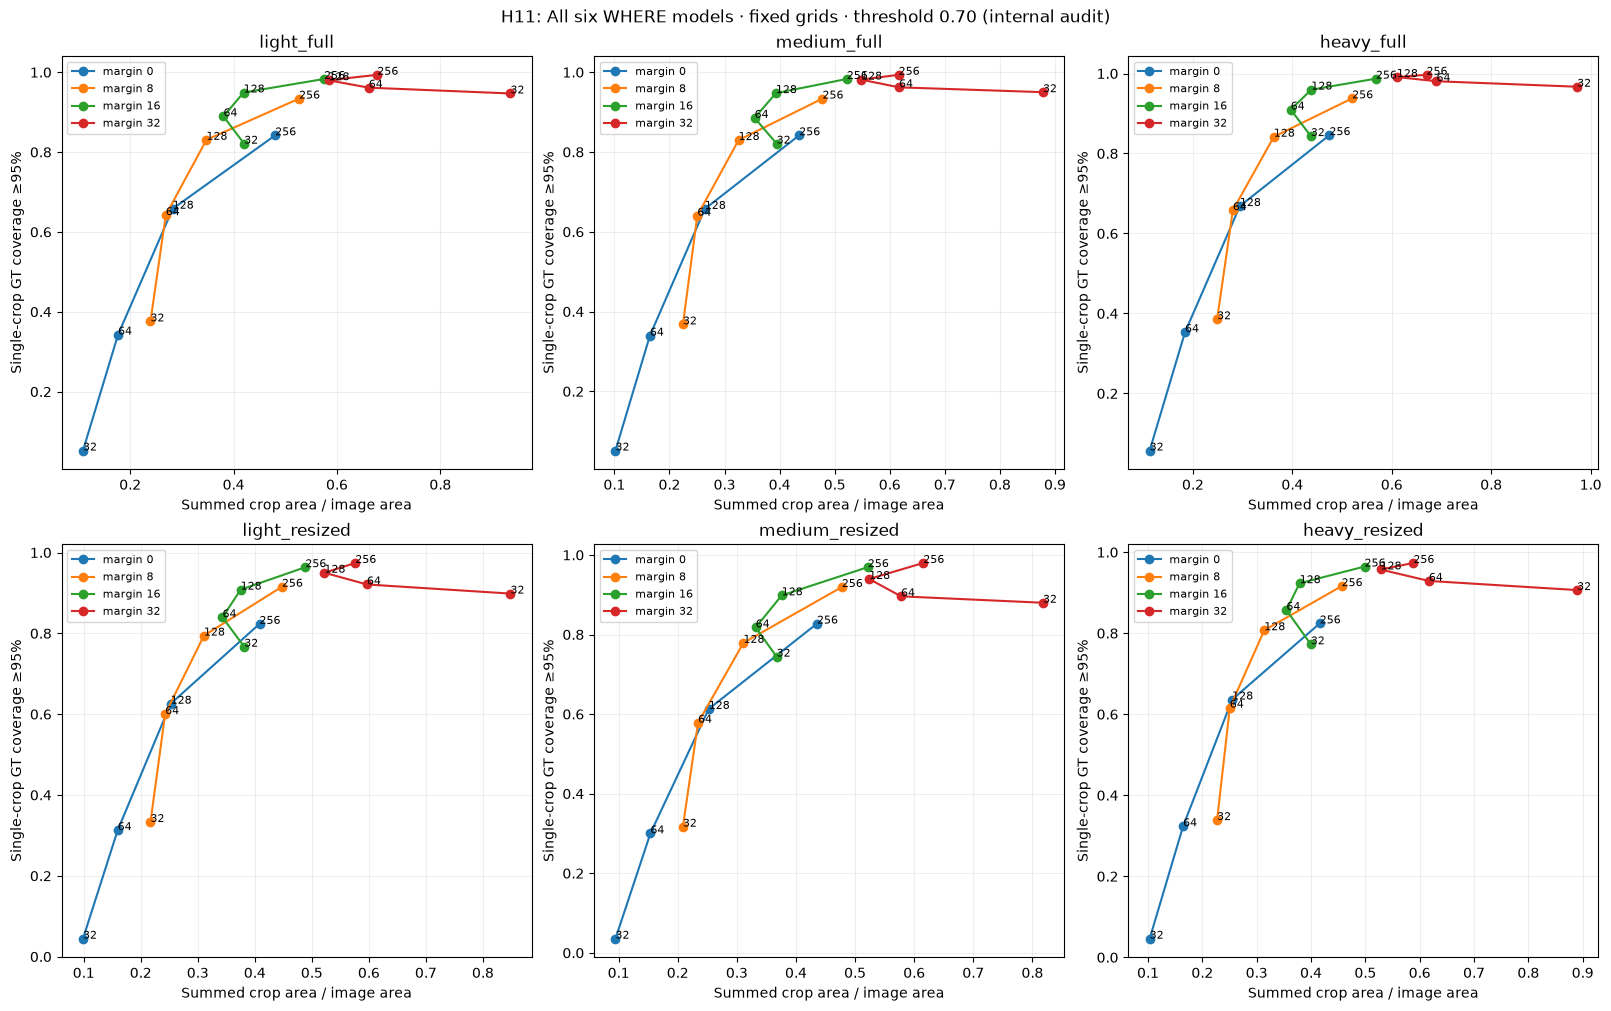

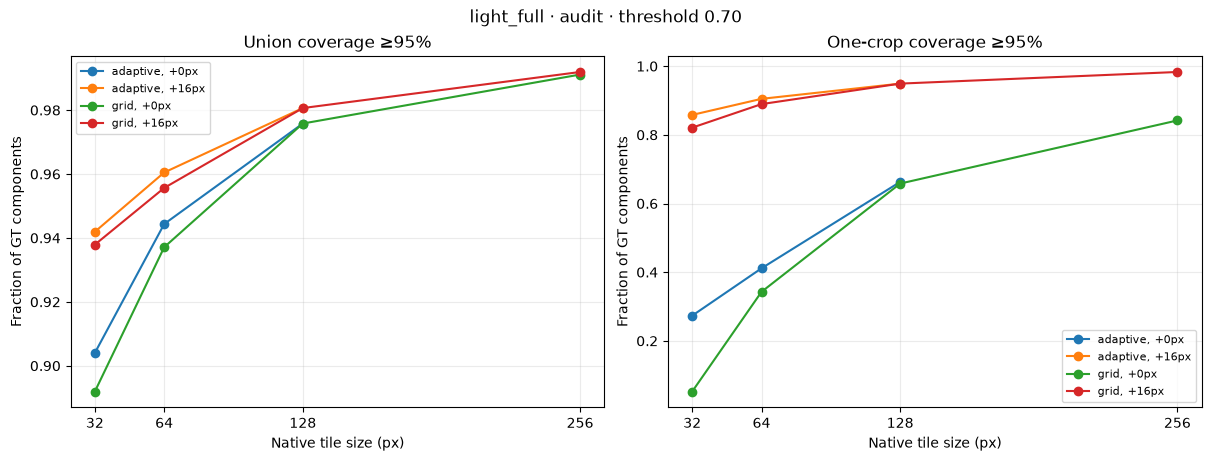

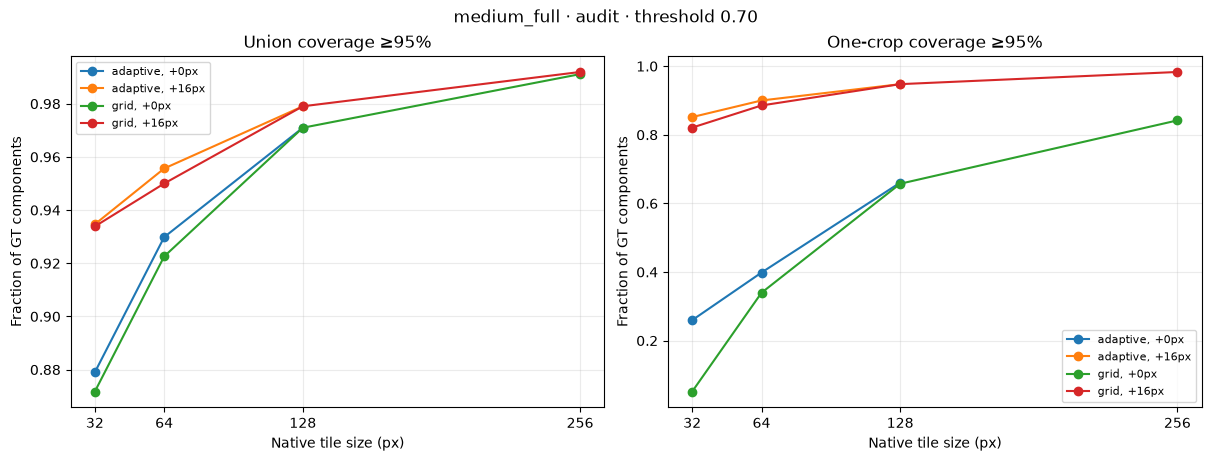

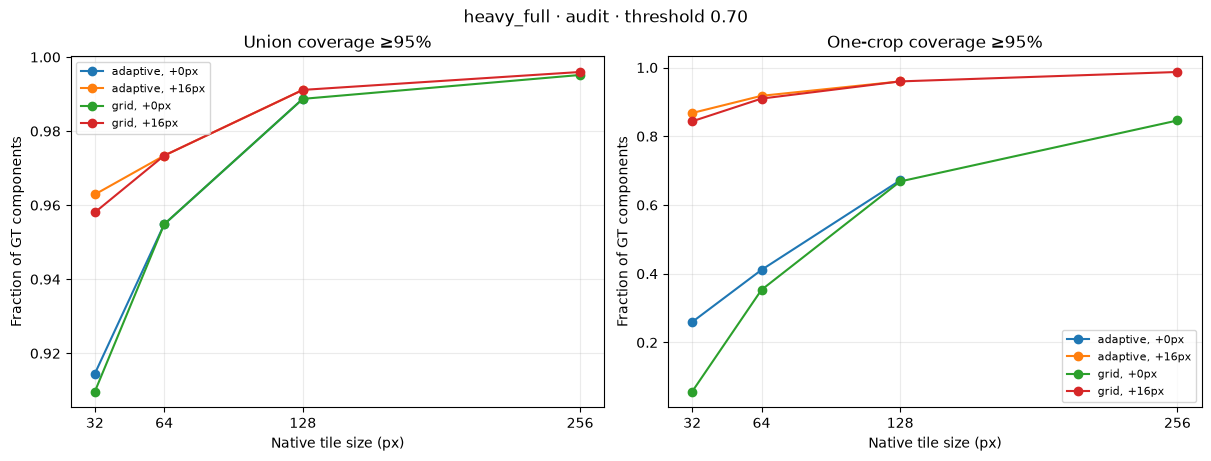

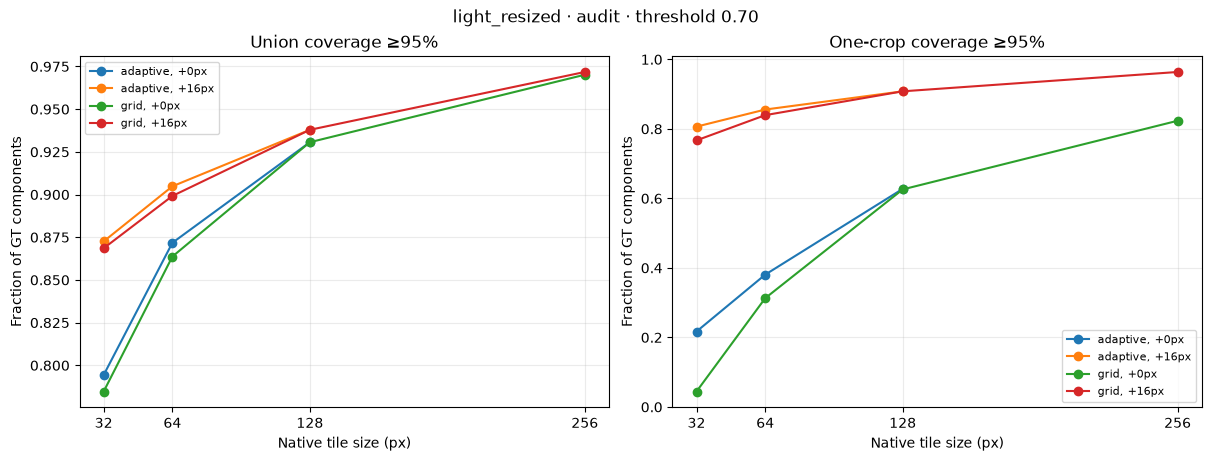

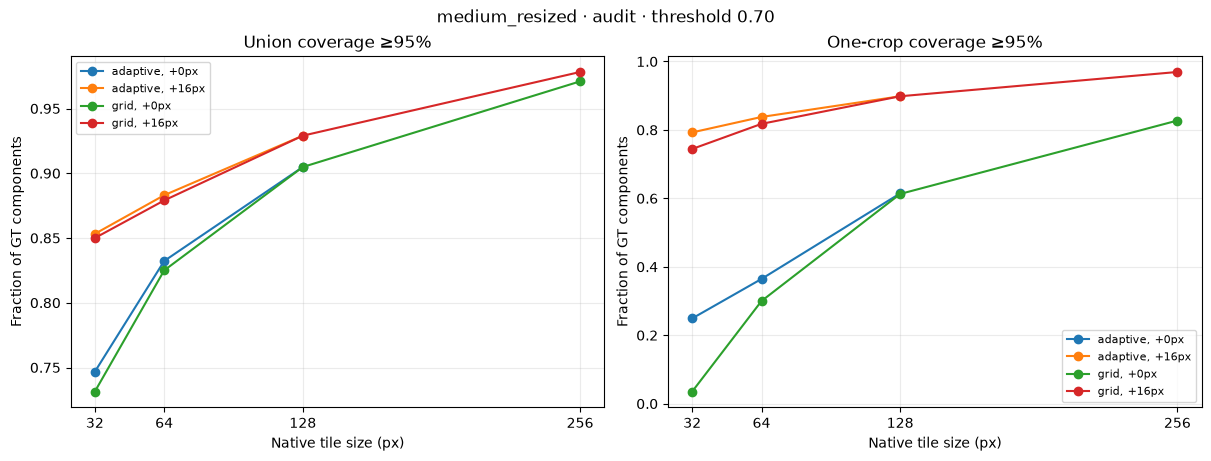

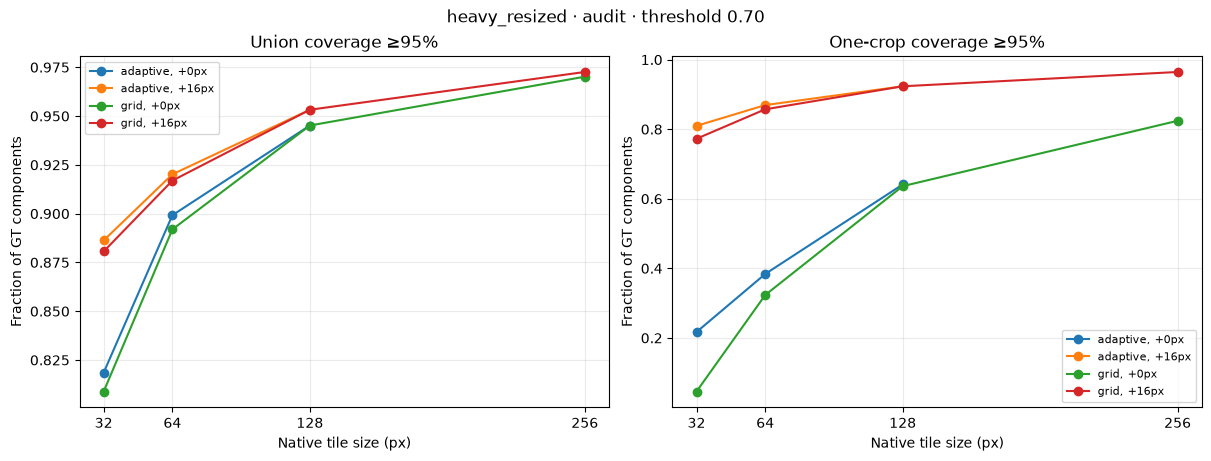

In [12]:
# One large figure with six model panels, plus one detailed figure per model.
model_order=list(MODELS)
fig,axes=plt.subplots(2,3,figsize=(16,10),constrained_layout=True)
for ax,model in zip(axes.ravel(),model_order):
    g=summary[(summary.candidate==model)&(summary.internal_split=='audit')&
              (summary.threshold==0.70)&(summary.algorithm=='grid')]
    for margin,sub in g.groupby('margin'):
        sub=sub.sort_values('tile_size')
        ax.plot(sub.processed_area_ratio,sub.roi_single_coverage95,marker='o',label=f'margin {margin}')
        for r in sub.itertuples():
            ax.annotate(str(r.tile_size),(r.processed_area_ratio,r.roi_single_coverage95),fontsize=8)
    ax.set_title(model)
    ax.set_xlabel('Summed crop area / image area')
    ax.set_ylabel('Single-crop GT coverage ≥95%')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle('H11: All six WHERE models · fixed grids · threshold 0.70 (internal audit)')
fig.savefig(OUTPUT/'figures'/'11_all_six_single_crop_coverage_vs_area.png',dpi=160)
plt.show()

for model in MODELS:
    sub=summary[(summary.candidate==model)&(summary.internal_split=='audit')&
                (summary.threshold==0.70)&(summary.algorithm.isin(['grid','adaptive']))]
    fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
    for (alg,margin),g in sub.groupby(['algorithm','margin']):
        if margin not in (0,16):continue
        g=g.sort_values('tile_size');name=f'{alg}, +{margin}px'
        axes[0].plot(g.tile_size,g.roi_union_coverage95,marker='o',label=name)
        axes[1].plot(g.tile_size,g.roi_single_coverage95,marker='o',label=name)
    axes[0].set_title('Union coverage ≥95%')
    axes[1].set_title('One-crop coverage ≥95%')
    for ax in axes:
        ax.set_xlabel('Native tile size (px)');ax.set_ylabel('Fraction of GT components')
        ax.set_xticks(GRID_SIZES);ax.grid(alpha=.25);ax.legend(fontsize=8)
    fig.suptitle(model+' · audit · threshold 0.70')
    fig.savefig(OUTPUT/'figures'/f'11_{model}_grid_coverage.png',dpi=150)
    plt.show()

## 12 — Optional qualitative ROI examples

Shows the **same validation pair** with the **same model threshold**, changing only grid size/margin/adaptive choice. GT contours are shown for evaluation, not used to select ROIs. Example indices are predeclared, not cherry-picked after observing outcomes.

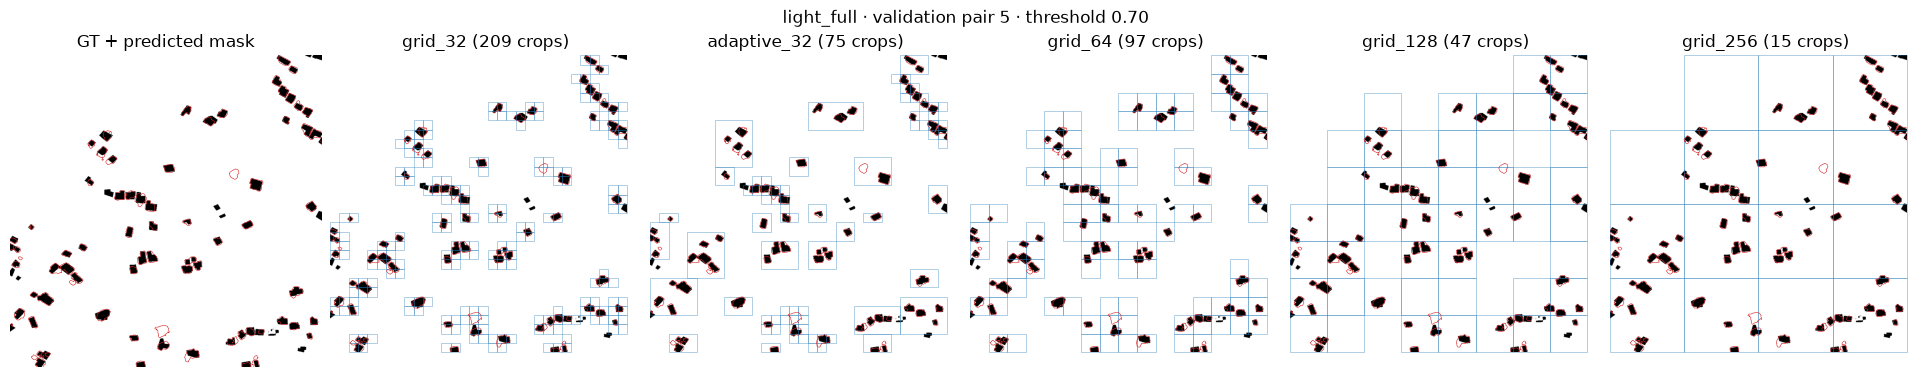

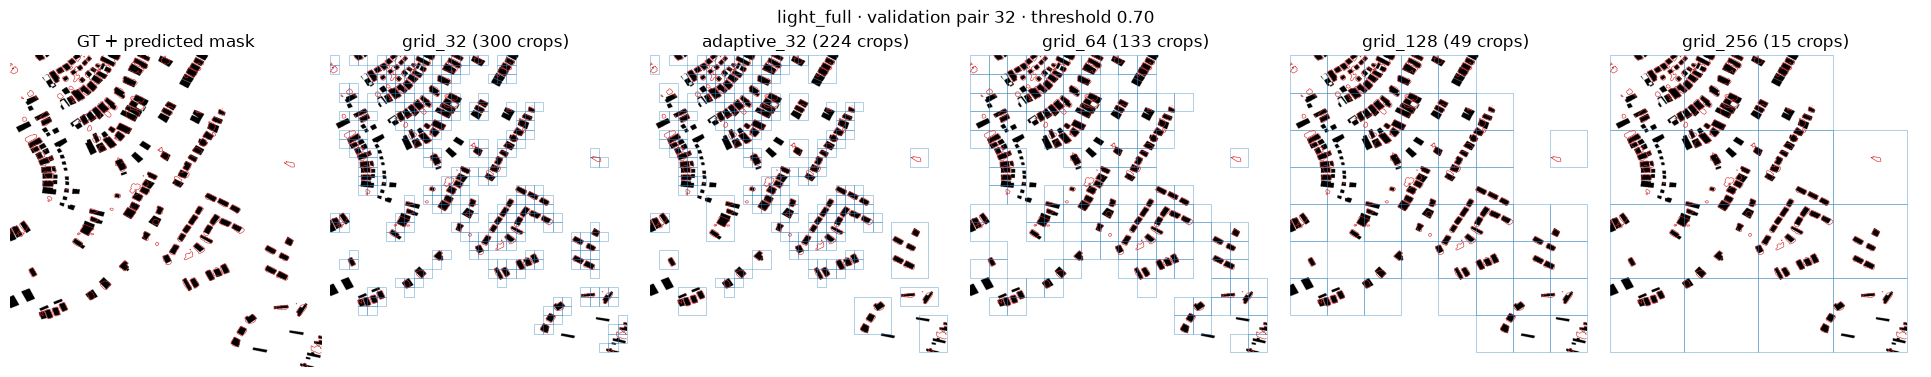

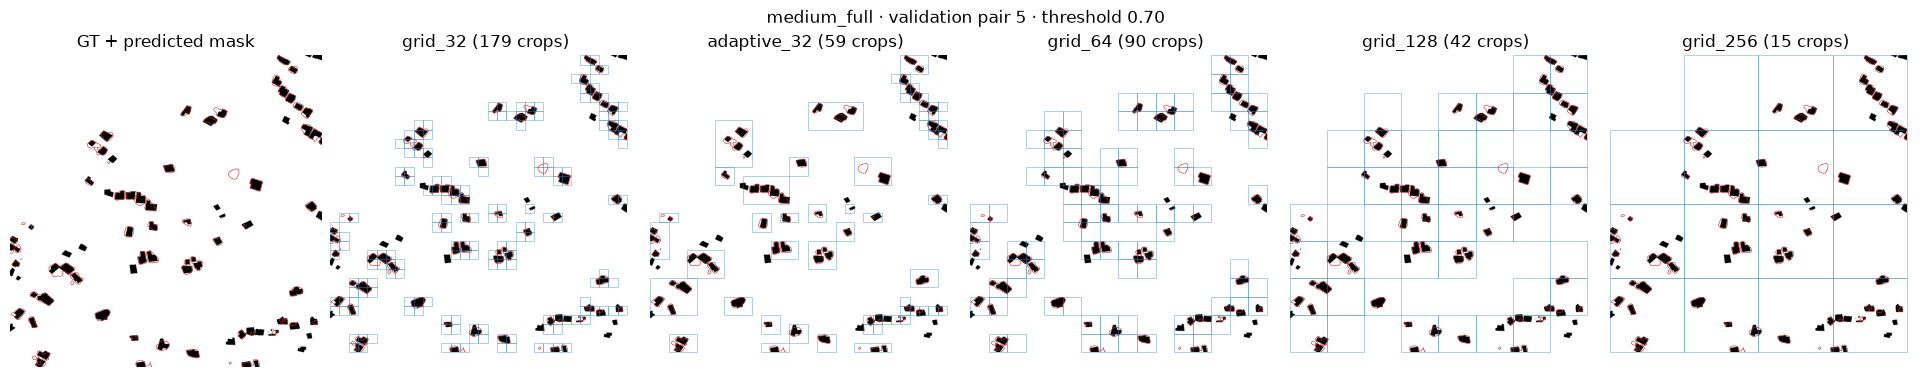

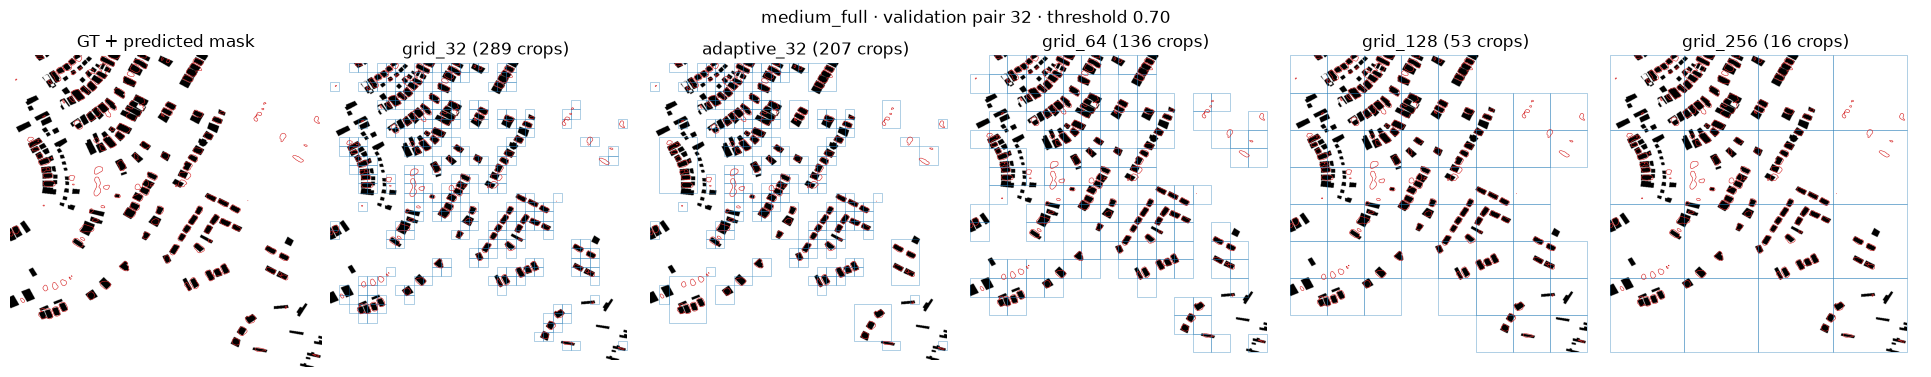

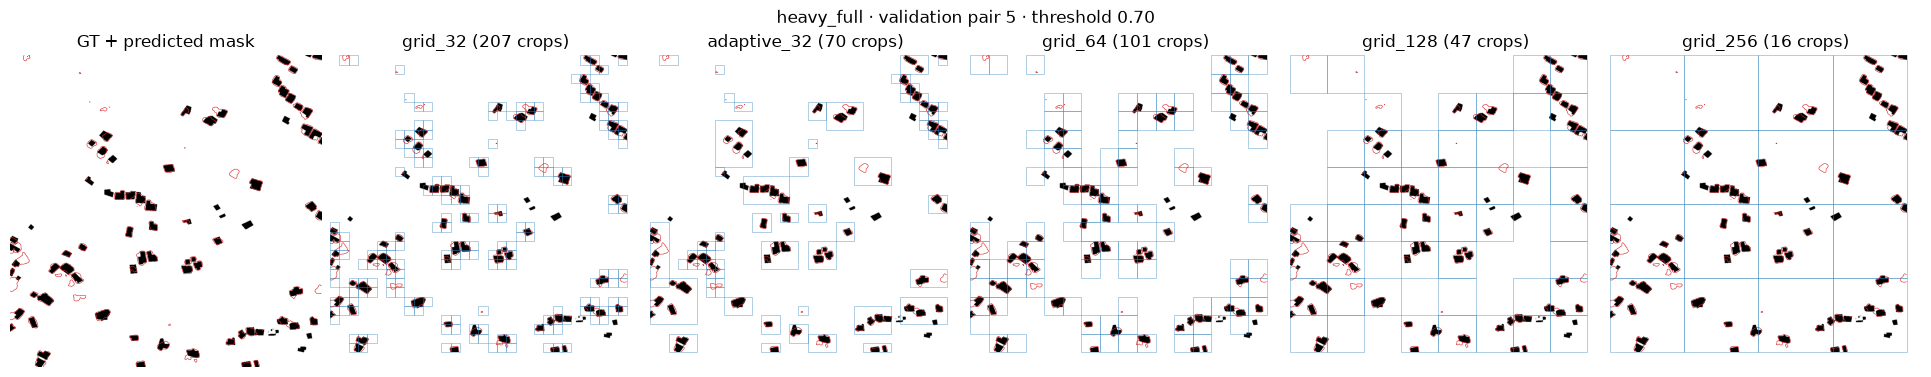

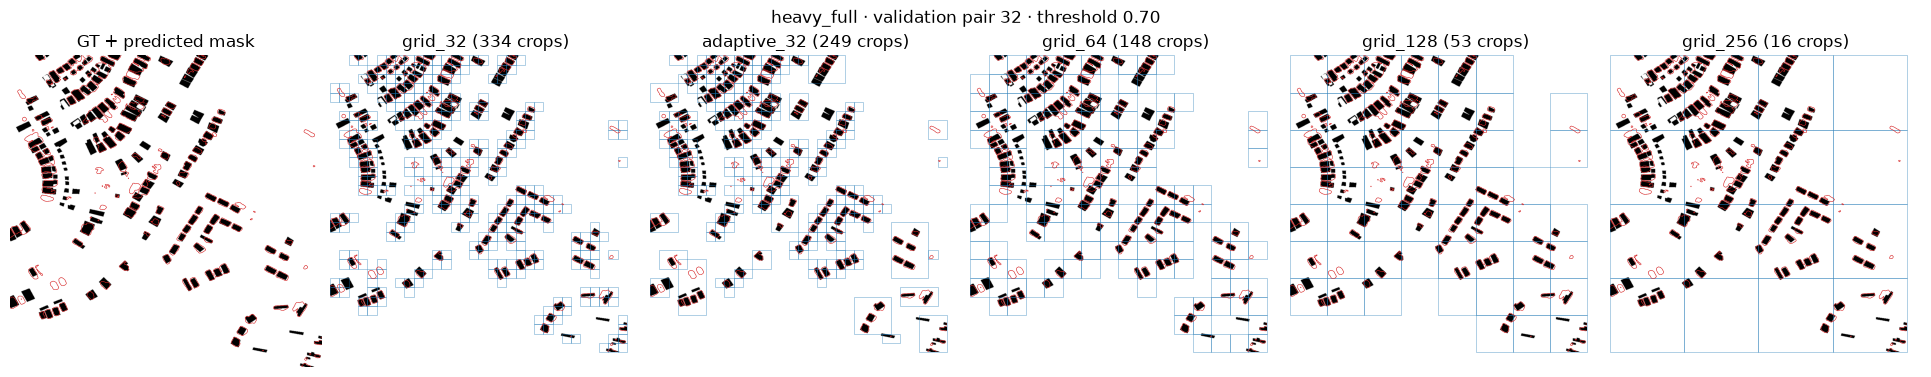

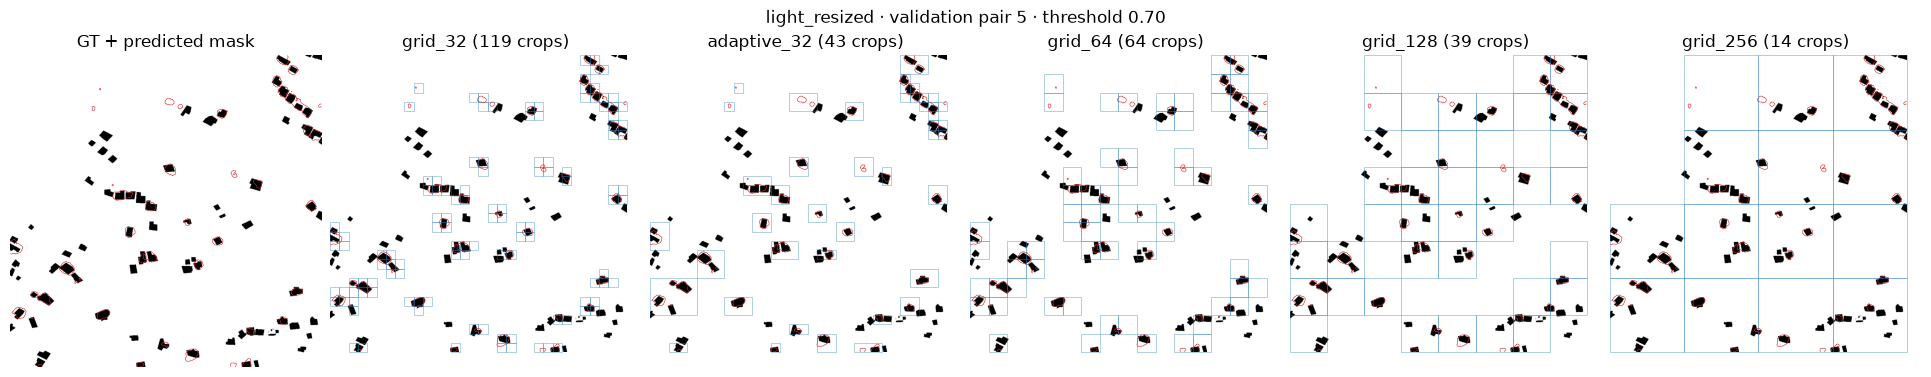

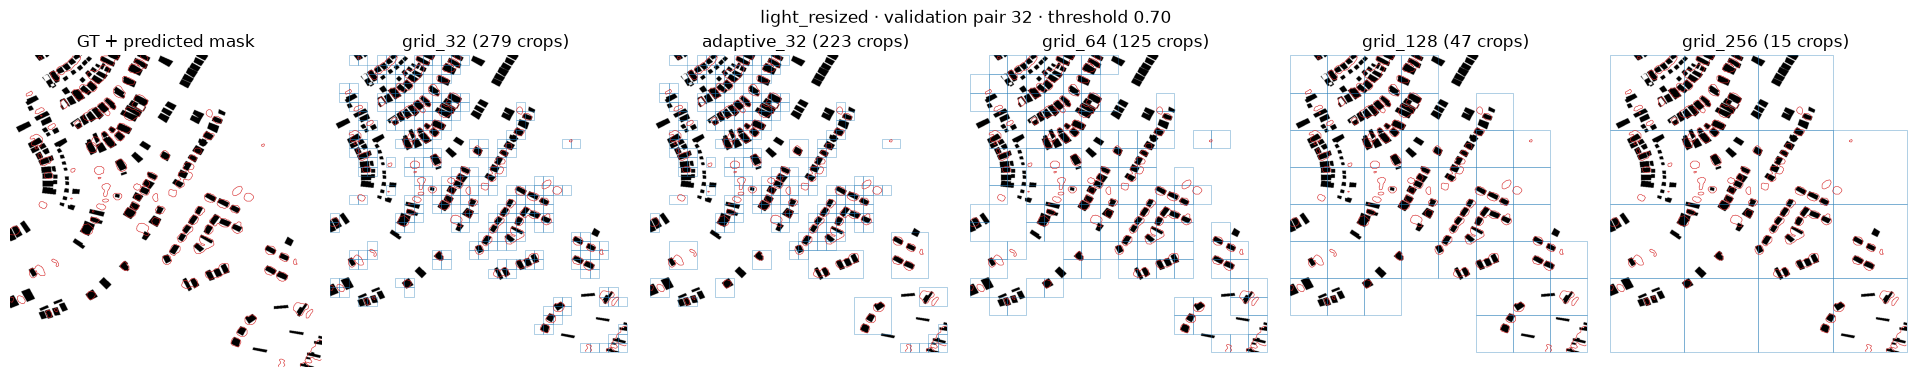

In [13]:
if RUN_CASE_VISUALS:
    for model in MODELS:
        for i in CASE_INDICES:
            if i >= N:continue
            gt=experiment.gt('val',i)
            binary=experiment.score(specs[model],'val',i)>=np.float32(.70)
            selected={}
            for alg,side,margin,boxes,_ms in propose_all(binary):
                if margin==0 and alg=='grid' and side in GRID_SIZES:
                    selected[f'grid_{side}']=boxes
                if alg=='adaptive' and side==32 and margin==0:
                    selected['adaptive_32']=boxes
            fig,axes=plt.subplots(1,len(selected)+1,figsize=(3.2*(len(selected)+1),3.7),constrained_layout=True)
            for ax in axes:
                ax.imshow(gt['mask'],cmap='Greys',vmin=0,vmax=1)
                ax.contour(binary.astype(float),levels=[.5],colors=['tab:red'],linewidths=.4)
                ax.set_axis_off()
            axes[0].set_title('GT + predicted mask')
            for ax,(name,boxes) in zip(axes[1:],selected.items()):
                for x0,y0,x1,y1 in boxes:
                    ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,
                                           edgecolor='tab:blue',linewidth=.45,alpha=.55))
                ax.set_title(f'{name} ({len(boxes)} crops)')
            fig.suptitle(f'{model} · validation pair {i} · threshold 0.70')
            fig.savefig(OUTPUT/'figures'/f'11_{model}_pair_{i:03d}.png',dpi=125)
            plt.show()

## 13 — Export full evidence and limitations

Upload the generated `H11_grid_tile_size_all_models_results.zip` to compare all six models. All numbers are from validation and audit only; never interpret them as independent SECOND semantic results. **Especially do not call per-crop overhead estimates measured latency.**

In [ ]:
manifest={
 'run':OUT_NAME,'created_utc':datetime.now(timezone.utc).isoformat(),
 'configuration':configuration,'configuration_sha256':config_sha,
 'experiment_signature':experiment.signature,'core_sha256':core_sha,
 'project_roi_module_sha256':roi_sha,'project_roi_module':str(project_roi_module.__file__),
 'validation_only':True,'uses_test':False,'retraining':False,'new_inference':False,
 'n_validation_pairs':N, 'dev_indices':sorted(dev_ids),'audit_indices':sorted(audit_ids),
 'run_complete':True,
 'limitations':[
    'LEVIR-CD validation only; validation internal audit is not an independent external test.',
    'Models were trained on building changes, not SECOND semantic classes.',
    'Union component coverage does not prove any single crop contains the full change.',
    'Single-crop component coverage does not establish semantic classification quality.',
    'Fixed-grid tile dimensions are in original GT image pixels, not resized model input pixels.',
    'WHAT costs are hypothetical proxy scenarios, not measured GPU latency.',
    'Adaptive ROI proposals are experimental and do not change src/satchange.',
    'The original test set was examined in H1-H10; none is used in H11.',
 ]
}
(OUTPUT/'11_run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
archive=OUTPUT/(OUT_NAME+'_results.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in sorted(OUTPUT.rglob('*')):
        if (p.is_file() and p!=archive and p.suffix.lower() in ('.csv','.png','.json')
                and 'shards' not in p.parts):
            z.write(p,p.relative_to(OUTPUT).as_posix())
print('Archive:',archive, '| MB:',round(archive.stat().st_size/1024**2,2))
display(FileLink(str(archive)))